# River Arrow (HARMONIOUS): que pasa cuando el agua no tiene nada que seguir

Notebook autocontenido que implementa **STIV** (*Space-Time Image Velocimetry*) sobre **OpenCV** y
lo aplica al River Arrow (Warwickshire, Inglaterra) desde una camara GoPro montada en un mastil.
pyorc no se importa en ningun momento.

Este caso **no** es un caso de medida mas. Es un **experimento controlado sobre el sembrado de
trazadores**, y esa es la razon de que exista. El dataset HARMONIOUS publica, para el mismo rio, la
misma camara, el mismo encuadre, la misma escala y el mismo numero de fotogramas, dos videos que se
diferencian **solo** en si alguien echo trazador al agua o no:

- `Arrow_GoPro_Unseeded_Stabilised.avi` -- superficie natural
- `Arrow_GoPro_Seeded_Stabilised.avi` -- con trazador sembrado

Los dos se procesan aqui con **exactamente la misma configuracion**, sin tocar una sola constante
entre uno y otro. Todo lo que difiera en el resultado es atribuible al sembrado y a nada mas, que
es la definicion de un experimento controlado. (El sembrado trae 98 fotogramas y el otro 99, un
fotograma de diferencia sobre casi cien: lo unico que no es identico entre los dos.)

## El resultado, por delante

El video **sin sembrar no es medible**. No es que salga impreciso: es que no hay senal. Su imagen
espacio-temporal es ruido blanco, sin ninguna estructura orientada, y los dos criterios de calidad
del notebook -- fijados de antemano, heredados de los otros casos del workspace, sin mirar estos
datos -- rechazan **el 100 %** de sus estaciones. El sembrado, sobre el mismo encuadre, da
coherencia mediana 0.93 y estelas de libro.

Y no es cuestion de haber elegido mal la configuracion. La **Parte 4c** se dedica entera a
intentar rescatarlo: nueve variantes que atacan cada hipotesis razonable sobre por que falla
(muestreo mas fino, bandas mas anchas, paso alto espacial, promediar secciones enteras, todo
combinado). Ninguna consigue una sola estacion de las 49. La razon de fondo tambien esta medida
alli, y es la que cierra el asunto: el dibujo de la superficie del agua **ya esta en nivel de ruido
en el salto de un fotograma**, que es el mas corto que el registro permite.

Eso no es un fracaso del notebook sino su conclusion, y es la razon de que STIV (y el PIV, y
cualquier tecnica de velocimetria por imagen) no sea una tecnica que se pueda aplicar a cualquier
video de un rio: **necesita que la superficie tenga textura que viaje con la corriente**. Cuando el
agua esta lisa, no la hay, y ninguna cantidad de proceso la inventa.

Los pasos son los mismos de siempre:

1. Abrir los dos videos y mirarlos
2. Fijar la escala y la geometria de las cinco secciones de aforo
3. Construir las imagenes espacio-temporales (STI) sobre las lineas de busqueda
4. Medir la pendiente de las estelas con el tensor de estructura, y filtrar las malas
4c. Intentar rescatar el video sin sembrar, y averiguar por que no se puede
5. Componer los perfiles transversales

**No hay ningun detector automatico.** Todo lo que depende del caso es una constante marcada
`>>> AJUSTABLE <<<`, al principio del bloque donde se usa. Las que salen del dataset llevan la marca
*(obtenido del dataset)*. **Los datos de entrada se leen en modo solo lectura; todo lo generado va
a `salidas/`.**

## Lo que este caso tiene de facil, y lo que tiene de dificil

Facil: como en el rio Bradano, el dataset entrega los videos **ya ortorrectificados y
estabilizados**, y declara la escala (0.0174 m/px). No hay geometria que resolver -- ni GCPs, ni
homografia, ni `solvePnP`. El fotograma *es* el plano del agua.

Dificil, aparte del sembrado: el video es **corto y lento**. 99 fotogramas a 5 Hz son 19.8 s, pero
solo 99 filas de STI, frente a las 600 del Bradano o las 250 del Sile Main Canal. Con tan pocas
filas, los bloques del tensor tienen que ser mas pequenos y hay menos de los que promediar. Y el
encuadre es de 464x505 px, asi que las lineas de busqueda de las secciones de los extremos se salen
del fotograma y hay que recortarlas, como en el caso de Hommerich.

---
## Parte 0 - Rutas de trabajo

Los datos viven **fuera del workspace**, asi que las rutas de entrada son absolutas a proposito.
El notebook se ejecuta desde su propia carpeta y todo lo que genera va a `salidas/`.

Se usan las versiones de la carpeta `Stabilised`, y no es indiferente: el `Readme.txt` dice que las
coordenadas en pixeles de los datos de validacion estan referidas **al primer fotograma de la
imagen estabilizada**. Se comprobo ademas que el primer fotograma del video coincide con la primera
imagen de la carpeta `Frames` (correlacion de fase: desplazamiento 0.00 px), o sea que video e
imagenes extraidas comparten rejilla y las coordenadas de referencia valen tal cual.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)

# --- Entradas (nunca se modifican) ---
DIR_DATOS = Path(r"C:\Users\Sergio\Desktop\datasets vision velocimetria\data\RiverArrow")
DIR_STAB = DIR_DATOS / "Stabilised"

# Los dos videos del experimento. El primero es el caso principal; el segundo es el control.
VIDEOS = {
    "sin sembrar": DIR_STAB / "GoPro_Stable_trans_Unseeded" / "Video" / "Arrow_GoPro_Unseeded_Stabilised.avi",
    "sembrado":    DIR_STAB / "GoPro_stable_trans_seeded" / "Video" / "Arrow_GoPro_Seeded_Stabilised.avi",
}
CASO_PRINCIPAL = "sin sembrar"
CASO_CONTROL = "sembrado"

# Del fichero de validacion se leen en la Parte 2 SOLO las coordenadas de las verticales.
# La columna de velocidades no se abre hasta la Parte 7.
ARCHIVO_VALIDACION = DIR_DATOS / "Reference" / "Validation_Data_Arrow_GoPro.xlsx"

# --- Salidas ---
DIR_SALIDA = Path("salidas")
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config_stiv.json"
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"
SALIDA_RESUMEN = DIR_SALIDA / "resumen.csv"
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"

benchmark.reiniciar()

print("Dataset en:", DIR_DATOS)
for etq, v in VIDEOS.items():
    print(f"  {'OK   ' if v.exists() else 'FALTA'} [{etq:11s}] {v.name}")
print(f"  {'OK   ' if ARCHIVO_VALIDACION.exists() else 'FALTA'} {ARCHIVO_VALIDACION.name}")

Dataset en: C:\Users\Sergio\Desktop\datasets vision velocimetria\data\RiverArrow
  OK    [sin sembrar] Arrow_GoPro_Unseeded_Stabilised.avi
  OK    [sembrado   ] Arrow_GoPro_Seeded_Stabilised.avi
  OK    Validation_Data_Arrow_GoPro.xlsx


---
## Parte 1 - Los dos videos

De los metadatos salen la **cadencia** (para convertir fotogramas en segundos) y el fotograma sobre
el que comprobar la geometria. Los dos videos tienen que coincidir en todo: si no, no seria un
experimento controlado.

Junto al primer fotograma se dibuja el mapa de **desviacion tipica temporal** de cada pixel. Es la
figura que ya adelanta el resultado del notebook, antes de haber medido nada: en el video sembrado
las particulas dibujan las lineas de corriente, y en el video sin sembrar no hay nada que dibujar.
La desviacion tipica temporal es exactamente la materia prima de STIV -- lo que cambia con el
tiempo en un punto fijo -- y su ausencia es la ausencia de la senal.

In [2]:
info, frames, pilas = {}, {}, {}

for etq, ruta in VIDEOS.items():
    cap = cv2.VideoCapture(str(ruta))
    if not cap.isOpened():
        raise SystemExit(f"No se pudo abrir {ruta}")
    info[etq] = dict(
        fps=cap.get(cv2.CAP_PROP_FPS),
        n=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        ancho=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        alto=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
    )
    cap.release()
    print(f"[{etq:11s}] {info[etq]['ancho']}x{info[etq]['alto']}  "
          f"{info[etq]['fps']:.2f} fps  {info[etq]['n']} fotogramas "
          f"({info[etq]['n']/info[etq]['fps']:.1f} s)")

FPS = info[CASO_PRINCIPAL]["fps"]
DT = 1.0 / FPS
ANCHO_PX = info[CASO_PRINCIPAL]["ancho"]
ALTO_PX = info[CASO_PRINCIPAL]["alto"]
N_TOTAL = info[CASO_PRINCIPAL]["n"]

if {(i["fps"], i["ancho"], i["alto"]) for i in info.values()}.__len__() != 1:
    raise SystemExit("Los dos videos no comparten formato: no seria un experimento controlado.")
print(f"\nLos dos videos comparten formato y cadencia. DT = {DT*1000:.1f} ms")

[sin sembrar] 464x505  5.00 fps  99 fotogramas (19.8 s)
[sembrado   ] 464x505  5.00 fps  98 fotogramas (19.6 s)

Los dos videos comparten formato y cadencia. DT = 200.0 ms


  [bench] Parte 1: cargar el video [sin sembrar]: 0.7 s | CPU 0.8 s (1.1 nucleos) | RAM pico 337 MB


  [bench] Parte 1: cargar el video [sembrado]: 0.8 s | CPU 0.9 s (1.2 nucleos) | RAM pico 347 MB


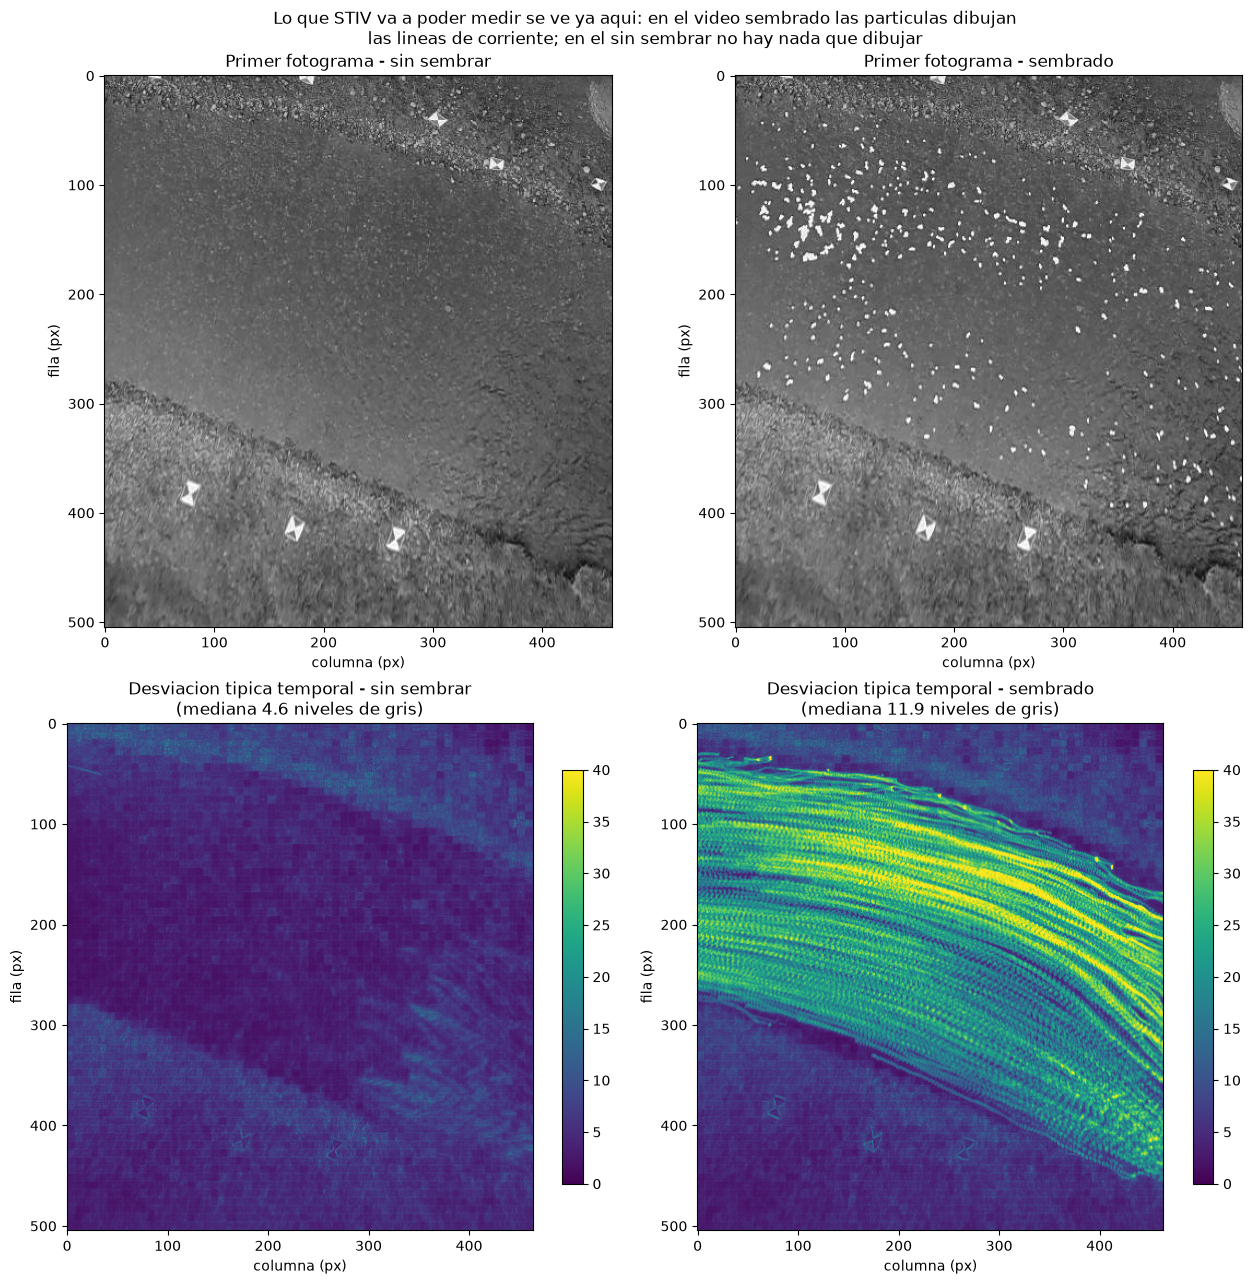

In [3]:
# Se cargan los dos videos enteros: son 99 fotogramas de 464x505, unos 23 MB cada uno en
# float32. En los otros casos del workspace esto seria impensable (el Sile Main Canal son
# 250 fotogramas 4K), y es la razon de que aqui se pueda mirar el video entero de una vez.
def cargar(ruta, n_max=None):
    cap = cv2.VideoCapture(str(ruta))
    fs = []
    while n_max is None or len(fs) < n_max:
        ok, fr = cap.read()
        if not ok:
            break
        fs.append(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32))
    cap.release()
    return np.stack(fs)


for etq, ruta in VIDEOS.items():
    with benchmark.medir(f"Parte 1: cargar el video [{etq}]", n_frames=info[etq]["n"]):
        pilas[etq] = cargar(ruta)
    frames[etq] = pilas[etq][0]

fig, axes = plt.subplots(2, 2, figsize=(13, 13))
for j, etq in enumerate(VIDEOS):
    sd = pilas[etq].std(axis=0)
    axes[0, j].imshow(frames[etq], cmap="gray")
    axes[0, j].set_title(f"Primer fotograma - {etq}")
    im = axes[1, j].imshow(sd, cmap="viridis", vmin=0, vmax=40)
    axes[1, j].set_title(f"Desviacion tipica temporal - {etq}\n"
                         f"(mediana {np.median(sd):.1f} niveles de gris)")
    plt.colorbar(im, ax=axes[1, j], shrink=0.75)
    for ax in (axes[0, j], axes[1, j]):
        ax.set_xlabel("columna (px)"); ax.set_ylabel("fila (px)")
fig.suptitle("Lo que STIV va a poder medir se ve ya aqui: en el video sembrado las particulas "
             "dibujan\nlas lineas de corriente; en el sin sembrar no hay nada que dibujar",
             fontsize=12)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig1_los_dos_videos.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Escala y geometria de las secciones

### La escala la da el dataset

El `Readme.txt` del River Arrow declara que todos los fotogramas tienen una resolucion de
**0.0174 m/px**, porque el video ya viene ortorrectificado. Igual que en el Bradano, no hay que
deducir nada: la vista es plana y el fotograma es el plano del agua.

### Las cinco secciones

El dataset publica **cinco secciones de aforo** (XS1 a XS5), con 9 o 10 verticales cada una, y da
para cada vertical su posicion en pixeles. Esas posiciones son **geometria**, y se usan aqui igual
que el caso del Sile Main Canal usa las progresivas de su CSV de aforo: la columna de velocidades
es lo que no se toca hasta la Parte 7.

### La direccion del flujo: una por seccion, no una global

STIV necesita que le den la direccion del flujo. En los otros casos del workspace es **una sola
constante** para todo el fotograma, porque el tramo es recto. Aqui no lo es, y se nota: correlando
parches entre fotogramas consecutivos sobre el video sembrado, la direccion del agua va de
**+6 grados** arriba a la izquierda a **+39 grados** abajo a la derecha. El rio gira dentro del
encuadre.

La solucion no es barrer angulos hasta maximizar algo -- eso seria ajustar contra los propios datos
--, sino usar la geometria que el dataset ya da: **la normal a cada seccion**. Un aforador traza
sus secciones perpendiculares a la corriente, asi que esa normal *es* la direccion del flujo, y sale
de las coordenadas de los extremos de cada seccion sin mirar ninguna velocidad. Las cinco normales
valen +8.2, +13.3, +16.0, +13.9 y +12.8 grados, y siguen la misma tendencia que la medida.

### El recorte de las lineas

Las lineas de busqueda miden 240 px y el fotograma solo 464x505, asi que las de XS1 y XS5 -- que
estan pegadas a los bordes izquierdo y derecho -- se salen. Se **recortan a su tramo visible**, como
en el caso de Hommerich, y se anota la **cobertura** de cada una. La alternativa, descartarlas, seria
perder dos de las cinco secciones.

In [4]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria
# ---------------------------------------------------------------------------------------
# Escala de la imagen ortorrectificada, declarada por el Readme.txt del dataset para todos
# los fotogramas. No se deduce de nada: se toma. (obtenido del dataset)
ESCALA = 0.0174               # m/px

# Cobertura minima de una linea de busqueda dentro del fotograma para admitirla. Por debajo
# quedan tan pocas muestras que no cabe ni un bloque del tensor.
COBERTURA_MIN = 0.50

# Margen al borde del fotograma, en pixeles: una muestra mas cerca que esto del borde toma
# valores replicados, que son textura inventada.
MARGEN_BORDE = 5
# ---------------------------------------------------------------------------------------

# Las verticales de aforo, del fichero de validacion. SOLO las coordenadas: la columna de
# velocidades (la tercera) no se lee aqui. (obtenido del dataset)
_val = pd.read_excel(ARCHIVO_VALIDACION, header=None)
_filas, _seccion = [], None
for _, r in _val.iloc[11:].iterrows():
    etiqueta = str(r[0])
    if etiqueta.startswith("XS"):
        _seccion = etiqueta
    elif _seccion is not None and etiqueta.replace(".", "").isdigit():
        _filas.append((_seccion, float(r[0]), float(r[1])))
verticales = pd.DataFrame(_filas, columns=["seccion", "x", "y"])
SECCIONES = list(dict.fromkeys(verticales.seccion))
N_ESTACIONES = len(verticales)

# La direccion del flujo de cada seccion es su normal, calculada de los extremos.
angulos = {}
for sec in SECCIONES:
    p = verticales[verticales.seccion == sec][["x", "y"]].to_numpy()
    d = p[-1] - p[0]
    normal = np.array([d[1], -d[0]]) / np.linalg.norm(d)
    angulos[sec] = float(np.degrees(np.arctan2(normal[1], normal[0])))
verticales["angulo"] = verticales.seccion.map(angulos)

print(f"Escala declarada por el dataset: {ESCALA*1000:.2f} mm/px")
print(f"{len(SECCIONES)} secciones, {N_ESTACIONES} verticales en total\n")
for sec in SECCIONES:
    p = verticales[verticales.seccion == sec]
    largo = np.linalg.norm(p[["x", "y"]].to_numpy()[-1] - p[["x", "y"]].to_numpy()[0])
    print(f"  {sec}: {len(p):2d} verticales, {largo:5.1f} px = {largo*ESCALA:5.2f} m de ancho, "
          f"normal (direccion del flujo) = {angulos[sec]:+5.1f} grados")

Escala declarada por el dataset: 17.40 mm/px
5 secciones, 49 verticales en total

  XS1:  9 verticales, 211.1 px =  3.67 m de ancho, normal (direccion del flujo) =  +8.2 grados
  XS2: 10 verticales, 238.4 px =  4.15 m de ancho, normal (direccion del flujo) = +13.3 grados
  XS3: 10 verticales, 242.4 px =  4.22 m de ancho, normal (direccion del flujo) = +16.0 grados
  XS4: 10 verticales, 250.3 px =  4.36 m de ancho, normal (direccion del flujo) = +13.9 grados
  XS5: 10 verticales, 243.1 px =  4.23 m de ancho, normal (direccion del flujo) = +12.8 grados


---
## Parte 3 - Construccion de las imagenes espacio-temporales

### El paso de muestreo

Con la escala y la cadencia de este video, el agua avanza

$$ d = \frac{u\,\Delta t}{e} \approx \frac{0.45 \times 0.2}{0.0174} \approx 5\ \text{px por fotograma} $$

y la regla de siempre, $\Delta s = d$, deja las estelas a $45^\circ$, que es donde el error angular
pesa menos:

$$ \frac{\delta u}{u} = \frac{\delta\theta}{\sin\theta\,\cos\theta} $$

Notese que aqui $d$ no sale de una velocidad esperada inventada: correlando parches del video
sembrado entre fotogramas consecutivos salen 4.0 a 6.4 px/fotograma segun la zona. `V_ESPERADA`
= 0.45 m/s es el centro de ese rango. Para el video sin sembrar no se puede hacer esa medida
previa -- no hay con que --, y se usa el mismo valor: es parte de procesar los dos igual.

### La banda

Como en el caso del Bradano, cada estacion muestrea una **banda** de lineas paralelas cuyas STI se
promedian, en vez de una sola linea. Aqui la banda es estrecha (6 px, tres lineas) por una razon
geometrica: las verticales de una misma seccion estan a solo ~25 px unas de otras, asi que una
banda ancha mezclaria verticales contiguas. 6 px son un 24 % de esa separacion, la misma proporcion
que en el Bradano.

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Muestreo de la STI
# ---------------------------------------------------------------------------------------
# Orden de magnitud de la velocidad superficial, del que sale el paso de muestreo DS. No es
# un resultado ni un dato de validacion: es el centro del rango que da la correlacion de
# parches entre fotogramas consecutivos (4.0 a 6.4 px/fotograma segun la zona).
V_ESPERADA = 0.45             # m/s

# Fotogramas a procesar: el video entero, que son solo 99.
N_FRAMES = 99

# Longitud de cada linea de busqueda, en muestras. 48 muestras a DS px son 240 px = 4.2 m.
# Mas larga daria mejor estadistica pero se sale del fotograma en mas secciones.
LARGO_STI = 48

# Banda de lineas paralelas. Estrecha, porque las verticales de una seccion estan a ~25 px.
ANCHO_BANDA = 6
PASO_BANDA = 3
# ---------------------------------------------------------------------------------------

D_ESPERADO = V_ESPERADA * DT / ESCALA
DS = int(round(D_ESPERADO))
SIGMA_ANTIALIAS = 0.5 * DS
offsets_banda = np.arange(-ANCHO_BANDA / 2, ANCHO_BANDA / 2 + 1e-9, PASO_BANDA)
N_BANDA = len(offsets_banda)

print(f"Desplazamiento esperado: {D_ESPERADO:.2f} px/fotograma")
print(f"  -> paso de muestreo  DS    = {DS} px  ({DS*ESCALA*100:.2f} cm)")
print(f"  -> filtro antialias  SIGMA = {SIGMA_ANTIALIAS:.1f} px")
print(f"  -> estelas a {np.degrees(np.arctan(D_ESPERADO/DS)):.1f} grados")
print(f"\nBanda: {N_BANDA} lineas separadas {PASO_BANDA} px")
print(f"Cada linea: {LARGO_STI} muestras x {DS} px = {LARGO_STI*DS} px = "
      f"{LARGO_STI*DS*ESCALA:.2f} m de rio")


def geometria_lineas(verticales, ds, largo, offsets, ancho, alto, margen, cobertura_min):
    """Para cada vertical, las coordenadas de muestreo de su banda y su cobertura.

    Las muestras que caen fuera del fotograma se descartan (no se replican: eso seria
    textura inventada), asi que cada linea puede acabar con un numero distinto de muestras.
    """
    s = (np.arange(largo) - largo / 2) * ds
    salida = []
    for r in verticales.itertuples():
        ang = np.radians(r.angulo)
        ux, uy = np.cos(ang), np.sin(ang)
        px, py = -uy, ux
        X, Y = r.x + s * ux, r.y + s * uy
        dentro = ((X >= margen) & (X < ancho - margen)
                  & (Y >= margen) & (Y < alto - margen))
        cobertura = float(dentro.mean())
        mx = np.array([X[dentro] + o * px for o in offsets], np.float32)
        my = np.array([Y[dentro] + o * py for o in offsets], np.float32)
        salida.append(dict(mapx=mx, mapy=my, cobertura=cobertura,
                           n_muestras=int(dentro.sum()), ux=ux, uy=uy))
    return salida


lineas = geometria_lineas(verticales, DS, LARGO_STI, offsets_banda,
                          ANCHO_PX, ALTO_PX, MARGEN_BORDE, COBERTURA_MIN)
verticales["cobertura"] = [l["cobertura"] for l in lineas]
verticales["n_muestras"] = [l["n_muestras"] for l in lineas]

print("\nCobertura de las lineas dentro del fotograma, por seccion:")
print(verticales.groupby("seccion").cobertura.agg(["min", "max"]).round(3).to_string())

Desplazamiento esperado: 5.17 px/fotograma
  -> paso de muestreo  DS    = 5 px  (8.70 cm)
  -> filtro antialias  SIGMA = 2.5 px
  -> estelas a 46.0 grados

Banda: 3 lineas separadas 3 px
Cada linea: 48 muestras x 5 px = 240 px = 4.18 m de rio

Cobertura de las lineas dentro del fotograma, por seccion:
           min    max
seccion              
XS1      0.521  0.646
XS2      0.938  1.000
XS3      1.000  1.000
XS4      0.958  1.000
XS5      0.583  0.812


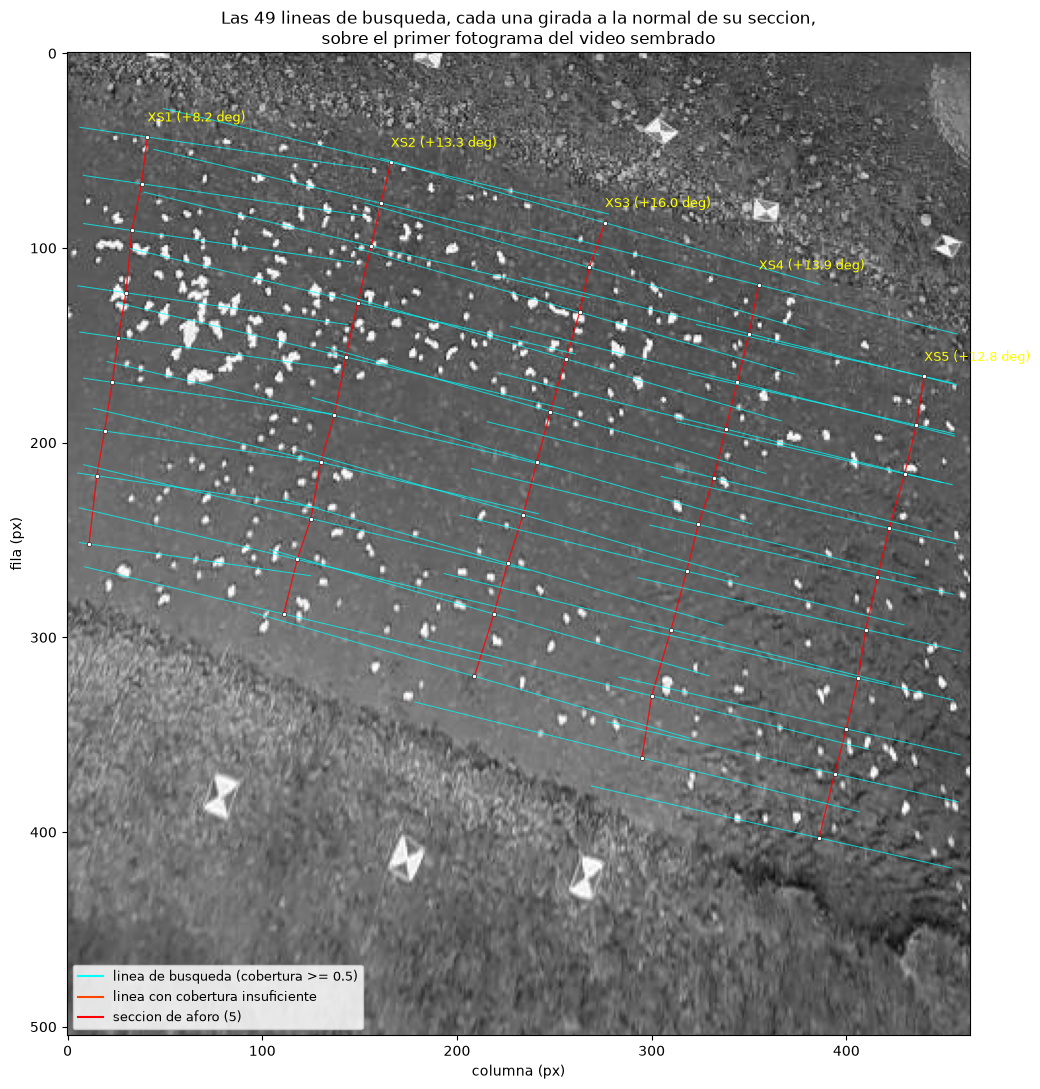

In [6]:
# Comprobacion visual de toda la geometria: las lineas de busqueda dibujadas con su
# inclinacion real sobre el fotograma sembrado, que es donde se ve el agua.
fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(frames[CASO_CONTROL], cmap="gray")
for sec in SECCIONES:
    sel = verticales.seccion == sec
    p = verticales[sel]
    ax.plot(p.x, p.y, "-", color="red", lw=1.0, alpha=0.8)
    ax.text(p.x.iloc[0], p.y.iloc[0] - 8, f"{sec} ({angulos[sec]:+.1f} deg)",
            color="yellow", fontsize=9)
for i, (r, l) in enumerate(zip(verticales.itertuples(), lineas)):
    color = "cyan" if l["cobertura"] >= COBERTURA_MIN else "orangered"
    ax.plot(l["mapx"][N_BANDA // 2], l["mapy"][N_BANDA // 2], color=color, lw=0.7, alpha=0.75)
    ax.plot(r.x, r.y, "o", color="white", ms=3, mec="k", mew=0.4)
ax.plot([], [], color="cyan", label=f"linea de busqueda (cobertura >= {COBERTURA_MIN})")
ax.plot([], [], color="orangered", label="linea con cobertura insuficiente")
ax.plot([], [], "-", color="red", label="seccion de aforo (5)")
ax.legend(loc="lower left", fontsize=9, framealpha=0.85)
ax.set_title(f"Las {N_ESTACIONES} lineas de busqueda, cada una girada a la normal de su seccion,\n"
             "sobre el primer fotograma del video sembrado")
ax.set_xlabel("columna (px)"); ax.set_ylabel("fila (px)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig2_geometria.png", dpi=115, bbox_inches="tight")
plt.show()

### Construccion y preparacion

La STI recien construida contiene dos cosas que no son la senal y que dominarian el tensor: el
**fondo estatico** de cada muestra (rayas verticales, que el tensor leeria como velocidad cero) y el
**parpadeo global** de cada fotograma (rayas horizontales, velocidad infinita). Se quitan restando
la media temporal por muestra y la media espacial por fotograma, y se normaliza dividiendo por la
desviacion tipica.

Esa normalizacion es tambien lo que permite **promediar las lineas de la banda entre si**: sin
ella, la linea mas brillante dominaria la media.

Antes de normalizar se guarda el **contraste temporal** de cada STI -- la desviacion tipica en el
tiempo, en niveles de gris --, porque la preparacion lo elimina por construccion y la Parte 4b lo
necesita.

In [7]:
def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)
    a = a - a.mean(axis=1, keepdims=True)
    d = a.std()
    return a / d if d > 0 else a


def construir_stis(pila, lineas, sigma):
    """STI preparada y contraste temporal de cada estacion, para un video ya cargado.

    Se filtra cada fotograma una sola vez y se muestrean todas las lineas sobre el resultado.
    """
    suaves = [cv2.GaussianBlur(f, (0, 0), sigma) for f in pila]
    stis, contrastes = [], []
    for l in lineas:
        banda = np.stack([
            np.stack([cv2.remap(f, l["mapx"][b:b + 1], l["mapy"][b:b + 1],
                                cv2.INTER_LINEAR)[0] for f in suaves])
            for b in range(l["mapx"].shape[0])
        ])                                   # (banda, t, muestras)
        cruda = banda.mean(axis=0)
        contrastes.append(float(cruda.std(axis=0).mean()))
        stis.append(np.mean([preparar_sti(banda[b]) for b in range(banda.shape[0])], axis=0))
    return stis, np.array(contrastes)


stis, contraste = {}, {}
for etq in VIDEOS:
    with benchmark.medir(f"Parte 3: construir las STI [{etq}]",
                         n_frames=len(pilas[etq]), lineas=N_ESTACIONES):
        stis[etq], contraste[etq] = construir_stis(pilas[etq], lineas, SIGMA_ANTIALIAS)
    print(f"[{etq:11s}] contraste temporal de las STI: "
          f"mediana {np.median(contraste[etq]):.2f}, rango "
          f"{contraste[etq].min():.2f} a {contraste[etq].max():.2f} niveles de gris")

  [bench] Parte 3: construir las STI [sin sembrar]: 0.7 s | CPU 0.7 s (1.0 nucleos) | RAM pico 469 MB
[sin sembrar] contraste temporal de las STI: mediana 0.71, rango 0.58 a 1.43 niveles de gris


  [bench] Parte 3: construir las STI [sembrado]: 0.8 s | CPU 0.7 s (0.9 nucleos) | RAM pico 469 MB
[sembrado   ] contraste temporal de las STI: mediana 6.74, rango 3.02 a 13.11 niveles de gris


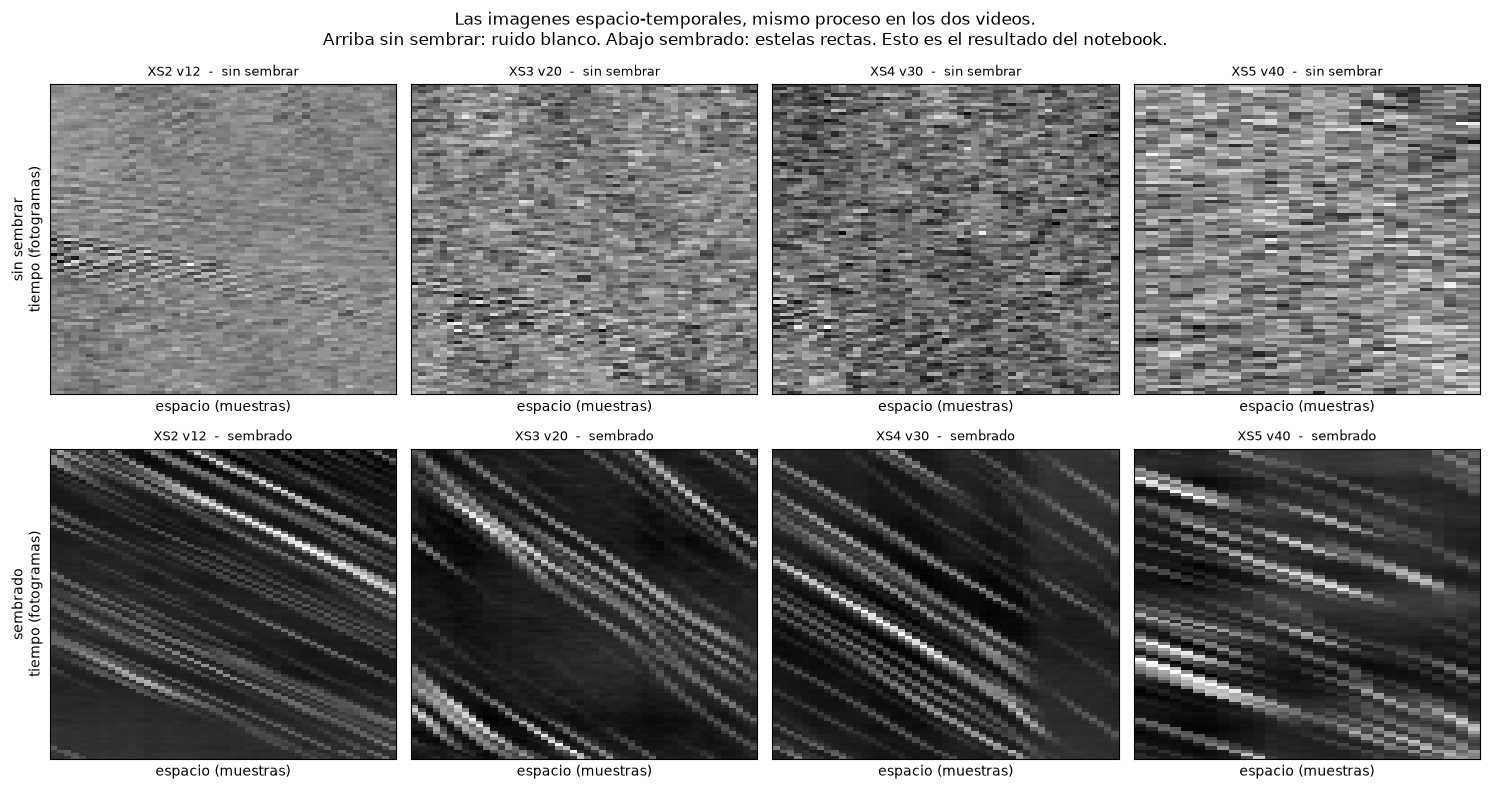

In [8]:
# La figura del notebook. Las mismas cuatro estaciones, en los dos videos, con exactamente
# el mismo proceso. A la izquierda no hay estelas; a la derecha son de libro.
DEMO = [12, 20, 30, 40]      # estaciones centrales de XS2, XS3, XS4 y XS5

fig, axes = plt.subplots(2, len(DEMO), figsize=(15, 8))
for fila, etq in enumerate(VIDEOS):
    for col, i in enumerate(DEMO):
        ax = axes[fila, col]
        ax.imshow(stis[etq][i], cmap="gray", aspect="auto")
        ax.set_title(f"{verticales.seccion[i]} v{i}  -  {etq}", fontsize=9)
        ax.set_xlabel("espacio (muestras)")
        if col == 0:
            ax.set_ylabel(f"{etq}\ntiempo (fotogramas)")
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Las imagenes espacio-temporales, mismo proceso en los dos videos.\n"
             "Arriba sin sembrar: ruido blanco. Abajo sembrado: estelas rectas. "
             "Esto es el resultado del notebook.", fontsize=12)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig3_sti_comparadas.png", dpi=115, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidad con el tensor de estructura

Sobre la STI preparada se calculan las derivadas en espacio y tiempo con Sobel, y se forma

$$ J \;=\; \begin{pmatrix} \sum I_x^2 & \sum I_x I_t \\[2pt] \sum I_x I_t & \sum I_t^2 \end{pmatrix} $$

El autovector del autovalor **menor** apunta a lo largo de las estelas; su pendiente $m = e_x/e_t$
es la velocidad en muestras por fotograma, y

$$ u = m\,\frac{\Delta s \cdot e}{\Delta t} $$

La **coherencia**

$$ C \;=\; \frac{\sqrt{(J_{xx}-J_{tt})^2 + 4J_{xt}^2}}{J_{xx}+J_{tt}} \;\in[0,1] $$

mide si hay una orientacion dominante. Es la magnitud que va a separar los dos videos.

### Bloques mas pequenos que en los otros casos

Se resuelve por bloques con 50 % de solape y se combinan por **mediana ponderada por coherencia**.
El lado del bloque es **24 px**, no los 64 del Bradano y del Sile Main Canal, y la razon es que este
video solo tiene 99 fotogramas: con bloques de 64 cabrian dos en el eje del tiempo, y la mediana
ponderada no tendria de que hacer mediana. Con 24 caben siete, y con las muestras del espacio salen
del orden de 14 bloques por estacion.

In [9]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Parametros del estimador
# ---------------------------------------------------------------------------------------
# Lado del bloque de STI, en pixeles de STI. 24 y no 64 porque el video tiene 99 fotogramas.
LADO_BLOQUE = 24

# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.45

# Suavizado gaussiano previo a las derivadas de Sobel, en pixeles de STI. Algo menor que en
# los otros casos, en proporcion al bloque mas pequeno.
SIGMA_DERIVADA = 1.2
# ---------------------------------------------------------------------------------------


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    g = cv2.GaussianBlur(bloque, (0, 0), sigma)
    It = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)[2:-2, 2:-2]
    Ix = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)[2:-2, 2:-2]

    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0

    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    return m, float(np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt))


def mediana_ponderada(valores, pesos):
    orden = np.argsort(valores)
    v, w = np.asarray(valores)[orden], np.asarray(pesos)[orden]
    return float(v[np.searchsorted(np.cumsum(w), 0.5 * w.sum())])


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE):
    """Pendiente robusta de una STI completa, por bloques con solape."""
    nt, nx = sti_p.shape
    if nt < lado or nx < lado:
        return np.nan, 0.0, 0, 0
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado])
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    if not ms:
        return np.nan, 0.0, 0, 0
    ms, cs = np.array(ms), np.array(cs)
    coh = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh, 0, len(ms)
    return mediana_ponderada(ms[usables], cs[usables]), coh, int(usables.sum()), len(ms)


def pendiente_a_velocidad(m):
    """m [muestras/fotograma] -> u [m/s]."""
    return m * DS * ESCALA / DT

In [10]:
v_bruta, coherencia, bloques = {}, {}, {}

for etq in VIDEOS:
    v = np.full(N_ESTACIONES, np.nan)
    c = np.zeros(N_ESTACIONES)
    b = np.zeros((N_ESTACIONES, 2), int)
    with benchmark.medir(f"Parte 4: tensor de estructura [{etq}]", lineas=N_ESTACIONES):
        for i in range(N_ESTACIONES):
            m, ci, nok, ntot = medir_sti(stis[etq][i])
            v[i] = abs(pendiente_a_velocidad(m)) if np.isfinite(m) else np.nan
            c[i] = ci
            b[i] = (nok, ntot)
    v_bruta[etq], coherencia[etq], bloques[etq] = v, c, b
    print(f"[{etq:11s}] coherencia mediana {np.median(c):.3f}, maxima {c.max():.3f}   "
          f"bloques por estacion: {b[:, 1].max()}")

resumen_partes = pd.DataFrame({
    "seccion": verticales.seccion,
    "x": verticales.x, "y": verticales.y,
    "cobertura": verticales.cobertura.round(3),
    "coh_sin_sembrar": coherencia[CASO_PRINCIPAL].round(3),
    "coh_sembrado": coherencia[CASO_CONTROL].round(3),
    "con_sin_sembrar": contraste[CASO_PRINCIPAL].round(2),
    "con_sembrado": contraste[CASO_CONTROL].round(2),
    "v_sin_sembrar": v_bruta[CASO_PRINCIPAL].round(3),
    "v_sembrado": v_bruta[CASO_CONTROL].round(3),
})
print()
print(resumen_partes.groupby("seccion").agg(
    coh_sin=("coh_sin_sembrar", "median"), coh_semb=("coh_sembrado", "median"),
    con_sin=("con_sin_sembrar", "median"), con_semb=("con_sembrado", "median"),
).round(3).to_string())

  [bench] Parte 4: tensor de estructura [sin sembrar]: 0.2 s | CPU 0.2 s (1.0 nucleos) | RAM pico 384 MB
[sin sembrar] coherencia mediana 0.196, maxima 0.595   bloques por estacion: 21
  [bench] Parte 4: tensor de estructura [sembrado]: 0.1 s | CPU 0.1 s (0.9 nucleos) | RAM pico 384 MB
[sembrado   ] coherencia mediana 0.927, maxima 0.981   bloques por estacion: 21

         coh_sin  coh_semb  con_sin  con_semb
seccion                                      
XS1        0.216     0.928    0.810     6.960
XS2        0.164     0.951    0.685     6.550
XS3        0.159     0.938    0.660     6.705
XS4        0.183     0.844    0.720     6.570
XS5        0.276     0.696    0.890     7.200


---
## Parte 4b - Control de calidad

Dos criterios, los mismos que ya usan los otros casos del workspace, y **los dos fijados de
antemano**. Esto es importante para que el experimento signifique algo: si los umbrales se
eligieran mirando estos resultados, que rechacen el video sin sembrar no probaria nada.

### 1. Coherencia

Es el criterio del caso del Sile Main Canal y del Bradano, con el **mismo valor, 0.70**. Mide si la
STI tiene una orientacion dominante.

### 2. Contraste temporal

Es la leccion de Boneyard Creek: una estructura estatica da una estela perfectamente coherente de
pendiente cero, asi que la coherencia sola no basta para saber si se esta mirando agua en
movimiento. El umbral se pone en **2.0 niveles de gris**, en el hueco que separa las dos
poblaciones medidas.

### 3. Cobertura

Ya visto en la Parte 2: una linea que se sale del fotograma no tiene muestras suficientes.

### Lo que no se hace

Las estaciones rechazadas **no se rellenan**, igual que en Boneyard Creek y en el Bradano: no hay
seccion que integrar -- el dataset no publica batimetria -- asi que rellenar solo seria inventar
datos. Y no se calcula caudal, por la misma razon.

In [11]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterios de aceptacion
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima. El MISMO valor que usan los casos del Sile Main Canal y del
# Bradano. No se ha ajustado para este notebook.
COH_MIN_ESTACION = 0.70

# Contraste temporal minimo de la STI, en niveles de gris. Criterio heredado de Boneyard
# Creek, donde separaba muro de agua por un factor 5. Aqui el hueco medido es igual de
# limpio y 2.0 cae en mitad de el.
CONTRASTE_MIN = 2.0
# ---------------------------------------------------------------------------------------

valida, v_final = {}, {}
for etq in VIDEOS:
    ok = ((verticales.cobertura.to_numpy() >= COBERTURA_MIN)
          & (coherencia[etq] >= COH_MIN_ESTACION)
          & (contraste[etq] >= CONTRASTE_MIN)
          & np.isfinite(v_bruta[etq]))
    valida[etq] = ok
    v_final[etq] = np.where(ok, v_bruta[etq], np.nan)

print("=" * 74)
print(f"{'video':<14}{'aceptadas':>12}{'coh mediana':>14}{'coh maxima':>13}"
      f"{'contraste mediano':>20}")
print("=" * 74)
for etq in VIDEOS:
    print(f"{etq:<14}{valida[etq].sum():>6}/{N_ESTACIONES:<5}"
          f"{np.median(coherencia[etq]):>14.3f}{coherencia[etq].max():>13.3f}"
          f"{np.median(contraste[etq]):>20.2f}")
print("=" * 74)

print(f"\nEl umbral de coherencia esta en {COH_MIN_ESTACION:.2f} y la coherencia MAXIMA de "
      f"las {N_ESTACIONES} estaciones\ndel video sin sembrar es "
      f"{coherencia[CASO_PRINCIPAL].max():.3f}: ni una sola lo alcanza.")
print(f"El umbral de contraste esta en {CONTRASTE_MIN:.1f} y el contraste MAXIMO del video "
      f"sin sembrar es\n{contraste[CASO_PRINCIPAL].max():.2f}, frente a un minimo de "
      f"{contraste[CASO_CONTROL][valida[CASO_CONTROL]].min():.2f} entre las aceptadas del sembrado.")
print("\nLos dos criterios, cada uno por su cuenta, separan los dos videos sin solapamiento.")

video            aceptadas   coh mediana   coh maxima   contraste mediano
sin sembrar        0/49            0.196        0.595                0.71
sembrado          44/49            0.927        0.981                6.74

El umbral de coherencia esta en 0.70 y la coherencia MAXIMA de las 49 estaciones
del video sin sembrar es 0.595: ni una sola lo alcanza.
El umbral de contraste esta en 2.0 y el contraste MAXIMO del video sin sembrar es
1.43, frente a un minimo de 3.02 entre las aceptadas del sembrado.

Los dos criterios, cada uno por su cuenta, separan los dos videos sin solapamiento.


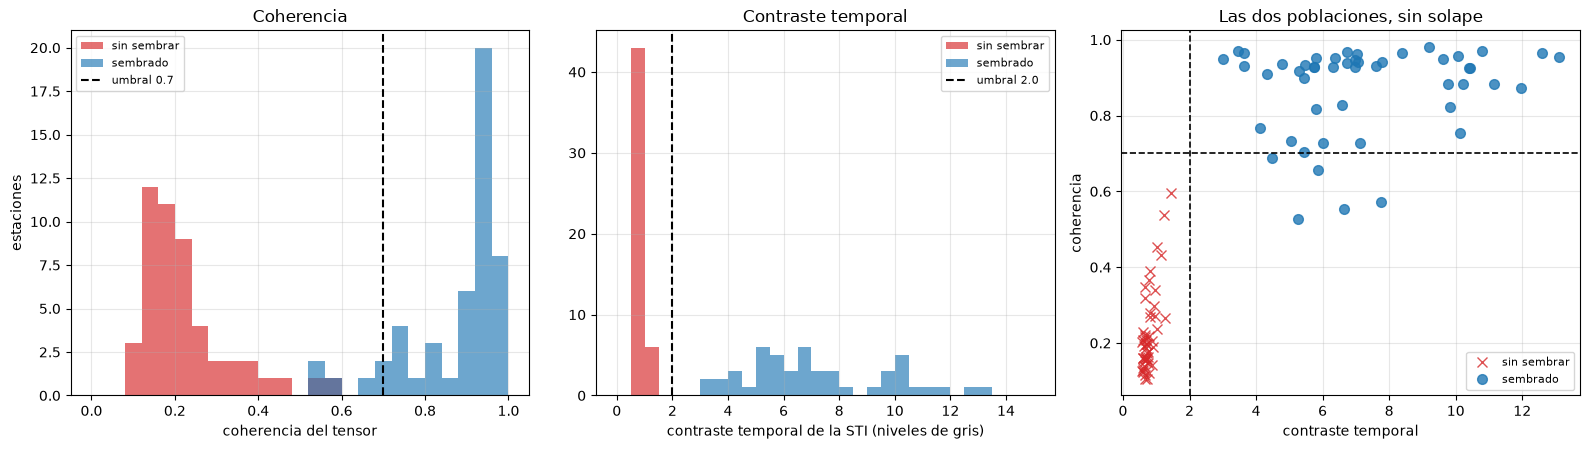

In [12]:
# Las dos poblaciones, dibujadas. Es la figura que convierte la tabla de arriba en un
# argumento: no hay solape, y los umbrales caen en tierra de nadie.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
for etq, color in zip(VIDEOS, ["tab:red", "tab:blue"]):
    ax.hist(coherencia[etq], bins=np.linspace(0, 1, 26), alpha=0.65, color=color, label=etq)
ax.axvline(COH_MIN_ESTACION, color="k", ls="--", lw=1.5,
           label=f"umbral {COH_MIN_ESTACION}")
ax.set_xlabel("coherencia del tensor"); ax.set_ylabel("estaciones")
ax.set_title("Coherencia"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
for etq, color in zip(VIDEOS, ["tab:red", "tab:blue"]):
    ax.hist(contraste[etq], bins=np.linspace(0, 15, 31), alpha=0.65, color=color, label=etq)
ax.axvline(CONTRASTE_MIN, color="k", ls="--", lw=1.5, label=f"umbral {CONTRASTE_MIN}")
ax.set_xlabel("contraste temporal de la STI (niveles de gris)")
ax.set_title("Contraste temporal"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[2]
for etq, color, marca in zip(VIDEOS, ["tab:red", "tab:blue"], ["x", "o"]):
    ax.plot(contraste[etq], coherencia[etq], marca, color=color, ms=7, alpha=0.8, label=etq)
ax.axvline(CONTRASTE_MIN, color="k", ls="--", lw=1.2)
ax.axhline(COH_MIN_ESTACION, color="k", ls="--", lw=1.2)
ax.set_xlabel("contraste temporal"); ax.set_ylabel("coherencia")
ax.set_title("Las dos poblaciones, sin solape")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_control_calidad.png", dpi=115, bbox_inches="tight")
plt.show()

---
## Parte 4c - Se puede rescatar el video sin sembrar?

La Parte 4b acaba de afirmar que el video sin sembrar no es medible. Dicho asi, esa afirmacion es
debil: lo unico que se ha demostrado es que **esta** configuracion no encuentra nada, y siempre
queda la sospecha de que con otro ajuste si. Esta parte se dedica a intentarlo en serio.

Se prueban nueve variantes sobre el video sin sembrar, cada una atacando una hipotesis distinta
sobre por que no hay senal:

- **Que el filtro antialias se la coma.** La textura natural del agua es mucho mas fina que una
  particula sembrada, y con `DS = 5` el desenfoque previo es de sigma 2.5 px, que borra todo lo que
  mida menos de eso. Se prueba muestreo fino con `DS = 2` y `DS = 1`, casi sin desenfoque.
- **Que la senal este, pero debil.** Es exactamente el problema del rio Bradano, y alli se resolvio
  ensanchando la banda de lineas paralelas. Se prueba con bandas de 30 y 60 px.
- **Que la tape el gradiente de iluminacion.** Se prueba un paso alto espacial (diferencia de
  gaussianas, sigma 6), que deja solo el detalle fino.
- **Que haga falta renunciar a la resolucion transversal.** Se prueba promediar las diez verticales
  de cada seccion en una sola STI: se pierde el perfil, pero se multiplica por diez la senal.
- Y todas las anteriores combinadas.

### Como se sabe si una variante ha encontrado algo de verdad

Esta es la parte importante, y este caso permite hacerlo bien. Subir la coherencia es facil: casi
cualquier filtro fabrica orientacion a partir del ruido. Lo que hace falta es un criterio externo, y
aqui lo hay: **el video sembrado es la verdad de campo del mismo sitio**. Se mide con la
configuracion del notebook, se quedan sus 43 estaciones buenas, y toda variante del video sin
sembrar se enfrenta a ellas estacion por estacion.

Si una variante recupera flujo real, tiene que **correlar con esa referencia interna**. Si sube la
coherencia sin subir la correlacion, lo que ha hecho es inventarse estructura.

Notese que esto **no usa ningun dato de validacion**: la referencia de esta parte es la medida del
otro video con este mismo codigo, no el aforo. El aforo sigue sin abrirse hasta la Parte 7.

In [13]:
def stis_variante(pila, lin, sigma, paso_alto=0.0):
    """STI preparada de cada estacion. Un solo `remap` por estacion y fotograma.

    `paso_alto` > 0 resta a cada fotograma su version muy desenfocada (filtro DoG), que
    elimina el gradiente de iluminacion y deja solo el detalle fino.
    """
    if paso_alto > 0:
        pila = [f - cv2.GaussianBlur(f, (0, 0), paso_alto) for f in pila]
    suaves = [cv2.GaussianBlur(f, (0, 0), max(sigma, 0.5)) for f in pila]
    salida = []
    for l in lin:
        if l["mapx"].shape[1] < LADO_BLOQUE + 2:
            salida.append(None); continue
        # remap admite el mapa 2D entero, asi que la banda sale de una sola llamada.
        banda = np.stack([cv2.remap(f, l["mapx"], l["mapy"], cv2.INTER_LINEAR,
                                    borderMode=cv2.BORDER_REPLICATE) for f in suaves])
        salida.append(np.mean([preparar_sti(banda[:, b, :])
                               for b in range(banda.shape[1])], axis=0))
    return salida


def medir_variante(pila, ds, largo, ancho_banda, paso_banda, paso_alto=0.0,
                   por_seccion=False):
    """Una variante completa. Devuelve velocidad y coherencia por estacion."""
    offs = (np.arange(-ancho_banda / 2, ancho_banda / 2 + 1e-9, paso_banda)
            if ancho_banda else np.array([0.0]))
    lin = geometria_lineas(verticales, ds, largo, offs, ANCHO_PX, ALTO_PX,
                           MARGEN_BORDE, COBERTURA_MIN)
    st = stis_variante(pila, lin, 0.5 * ds, paso_alto)
    v = np.full(N_ESTACIONES, np.nan)
    c = np.zeros(N_ESTACIONES)
    if por_seccion:
        for sec in SECCIONES:
            idx = [i for i in np.where((verticales.seccion == sec).to_numpy())[0]
                   if st[i] is not None]
            if not idx:
                continue
            n_min = min(st[i].shape[1] for i in idx)
            m, ci, _, _ = medir_sti(np.mean([st[i][:, :n_min] for i in idx], axis=0))
            for i in idx:
                v[i] = abs(m * ds * ESCALA / DT) if np.isfinite(m) else np.nan
                c[i] = ci
    else:
        for i, s in enumerate(st):
            if s is None:
                continue
            m, ci, _, _ = medir_sti(s)
            v[i] = abs(m * ds * ESCALA / DT) if np.isfinite(m) else np.nan
            c[i] = ci
    return v, c


# La referencia interna: el video sembrado medido con la configuracion del notebook. No es
# el aforo, que sigue cerrado hasta la Parte 7.
v_interna, c_interna = medir_variante(pilas[CASO_CONTROL], DS, LARGO_STI,
                                      ANCHO_BANDA, PASO_BANDA)
buena = (c_interna >= COH_MIN_ESTACION) & np.isfinite(v_interna)
print(f"Referencia interna (video sembrado, configuracion del notebook): "
      f"{buena.sum()} estaciones, mediana {np.nanmedian(v_interna[buena]):.3f} m/s\n")

VARIANTES = [
    ("configuracion del notebook", dict(ds=5, largo=48, ancho_banda=6, paso_banda=3)),
    ("muestreo fino DS=2 (casi sin desenfoque)", dict(ds=2, largo=110, ancho_banda=6, paso_banda=3)),
    ("muestreo finisimo DS=1", dict(ds=1, largo=200, ancho_banda=6, paso_banda=3)),
    ("banda ancha 30 px (el truco del Bradano)", dict(ds=5, largo=48, ancho_banda=30, paso_banda=3)),
    ("banda ancha 60 px", dict(ds=5, largo=48, ancho_banda=60, paso_banda=3)),
    ("paso alto espacial (DoG sigma 6)", dict(ds=5, largo=48, ancho_banda=6, paso_banda=3, paso_alto=6.0)),
    ("paso alto + banda 30", dict(ds=5, largo=48, ancho_banda=30, paso_banda=3, paso_alto=6.0)),
    ("una STI por seccion (10 verticales juntas)", dict(ds=5, largo=48, ancho_banda=6, paso_banda=3, por_seccion=True)),
    ("todo a la vez: DS=2, banda 30, paso alto", dict(ds=2, largo=110, ancho_banda=30, paso_banda=3, paso_alto=6.0)),
]

with benchmark.medir("Parte 4c: nueve variantes de rescate", n_frames=len(pilas[CASO_PRINCIPAL])):
    filas_rescate = []
    for nombre, kw in VARIANTES:
        v, c = medir_variante(pilas[CASO_PRINCIPAL], **kw)
        m = buena & np.isfinite(v)
        filas_rescate.append(dict(
            variante=nombre,
            aceptadas=int(((c >= COH_MIN_ESTACION) & np.isfinite(v)).sum()),
            coh_mediana=round(float(np.median(c)), 3),
            coh_maxima=round(float(c.max()), 3),
            r_vs_sembrado=(round(float(np.corrcoef(v[m], v_interna[m])[0, 1]), 3)
                           if m.sum() > 3 else np.nan),
        ))
rescate = pd.DataFrame(filas_rescate)
rescate.to_csv(DIR_SALIDA / "rescate_sin_sembrar.csv", index=False)

print(rescate.to_string(index=False, na_rep="  --"))
print(f"\nNinguna variante consigue una sola estacion por encima de "
      f"{COH_MIN_ESTACION}, de las {N_ESTACIONES} que hay.")
print("La correlacion con la referencia interna va de "
      f"{rescate.r_vs_sembrado.min():+.2f} a {rescate.r_vs_sembrado.max():+.2f}: erratica, "
      "que es como se comporta el ruido.")
print("\nEl paso alto es el unico que mueve la coherencia (0.196 -> 0.452), y es justo el que")
print("hay que mirar con desconfianza: sube la coherencia sin subir el acuerdo con la verdad.")
print("Esta fabricando orientacion a partir del residuo, no encontrando flujo.")

Referencia interna (video sembrado, configuracion del notebook): 43 estaciones, mediana 0.417 m/s



  [bench] Parte 4c: nueve variantes de rescate: 9.2 s | CPU 8.6 s (0.9 nucleos) | RAM pico 575 MB
                                  variante  aceptadas  coh_mediana  coh_maxima  r_vs_sembrado
                configuracion del notebook          0        0.196       0.595          0.045
  muestreo fino DS=2 (casi sin desenfoque)          0        0.206       0.369         -0.119
                    muestreo finisimo DS=1          0        0.248       0.339         -0.114
  banda ancha 30 px (el truco del Bradano)          0        0.197       0.649          0.282
                         banda ancha 60 px          0        0.203       0.532          0.402
          paso alto espacial (DoG sigma 6)          0        0.255       0.543          0.453
                      paso alto + banda 30          0        0.452       0.619          0.388
una STI por seccion (10 verticales juntas)          0        0.162       0.179             --
  todo a la vez: DS=2, banda 30, paso alto          0   

### Por que no hay nada que rescatar

Las nueve variantes dicen *que* no se puede, pero no *por que*. La razon se ve en una sola medida:
la **curva de decorrelacion**, que es cuanto sobrevive el dibujo de la superficie al pasar el
tiempo.

Se correlan parches del mismo sitio separados por un salto temporal creciente, y se toma el valor
del pico. Buscando el pico en toda la ventana, el desplazamiento no penaliza: lo unico que baja esa
curva es que el patron **deje de existir**. Es la magnitud que decide si algo es seguible, y no
depende del algoritmo que se use despues.

  [bench] Parte 4c: curvas de decorrelacion: 4.5 s | CPU 4.4 s (1.0 nucleos) | RAM pico 573 MB
 dt_fotogramas  dt_s  sin sembrar  sembrado
             1   0.2        0.055     0.725
             2   0.4        0.072     0.559
             3   0.6        0.054     0.428
             4   0.8        0.042     0.337
             6   1.2        0.035     0.215
             8   1.6        0.031     0.154

Desviacion tipica temporal en el video sin sembrar:
  agua           3.32 niveles de gris
  orilla (grava) 8.88 niveles de gris  <- estatica, y aun asi varia MAS


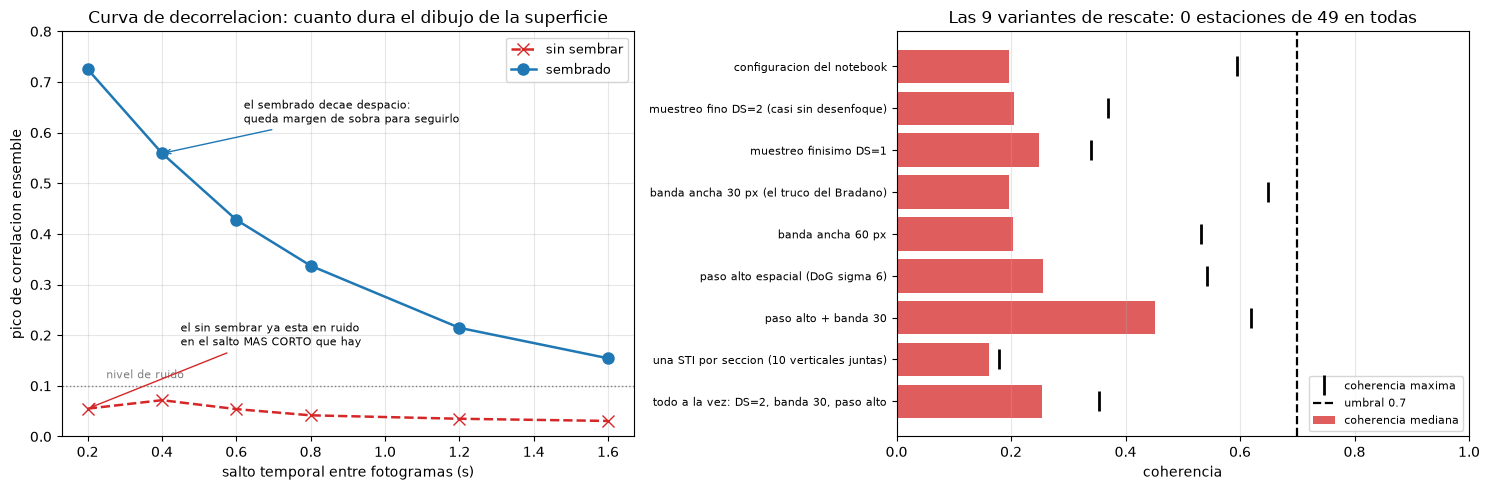

In [14]:
def curva_decorrelacion(pila, saltos, parches, radio=28):
    """Valor del pico de correlacion ensemble frente al salto temporal.

    El pico se busca en toda la ventana, asi que el desplazamiento no penaliza: lo unico que
    hace bajar la curva es que el patron deje de existir.
    """
    n = (pila - pila.mean(axis=0)) / (pila.std(axis=0) + 1e-6)
    fila = []
    for dt in saltos:
        busq = min(10 + 7 * dt, 60)
        picos = []
        for (x0, y0) in parches:
            acc = None
            for k in range(len(n) - dt):
                A = n[k, y0:y0 + 2 * radio, x0:x0 + 2 * radio]
                B = n[k + dt, max(y0 - busq, 0):y0 + 2 * radio + busq,
                      max(x0 - busq, 0):x0 + 2 * radio + busq]
                r = cv2.matchTemplate(B, A, cv2.TM_CCOEFF_NORMED)
                acc = r if acc is None else acc + r
            picos.append(float((acc / (len(n) - dt)).max()))
        fila.append(float(np.mean(picos)))
    return np.array(fila)


SALTOS = [1, 2, 3, 4, 6, 8]
PARCHES = [(150, 150), (250, 200), (200, 250)]     # parches de agua, lejos de las orillas

with benchmark.medir("Parte 4c: curvas de decorrelacion",
                     n_frames=sum(len(p) for p in pilas.values())):
    decorr = {etq: curva_decorrelacion(pilas[etq], SALTOS, PARCHES) for etq in VIDEOS}

tabla_decorr = pd.DataFrame({"dt_fotogramas": SALTOS,
                             "dt_s": [round(d * DT, 2) for d in SALTOS],
                             **{etq: np.round(decorr[etq], 3) for etq in VIDEOS}})
tabla_decorr.to_csv(DIR_SALIDA / "decorrelacion.csv", index=False)
print(tabla_decorr.to_string(index=False))

# La otra mitad del argumento: cuanta de la variacion temporal del video sin sembrar es
# senal y cuanta es ruido. Se compara el agua con un trozo de orilla, que no se mueve.
sd_sin = pilas[CASO_PRINCIPAL].std(axis=0)
sd_agua = float(np.median(sd_sin[150:300, 150:300]))
sd_orilla = float(np.median(sd_sin[0:40, 0:200]))
print(f"\nDesviacion tipica temporal en el video sin sembrar:")
print(f"  agua           {sd_agua:.2f} niveles de gris")
print(f"  orilla (grava) {sd_orilla:.2f} niveles de gris  <- estatica, y aun asi varia MAS")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
for etq, color, marca in zip(VIDEOS, ["tab:red", "tab:blue"], ["x--", "o-"]):
    ax.plot(np.array(SALTOS) * DT, decorr[etq], marca, color=color, ms=8, lw=1.8, label=etq)
ax.axhline(0.1, color="gray", ls=":", lw=1)
ax.text(0.25, 0.115, "nivel de ruido", fontsize=8, color="gray")
ax.set_xlabel("salto temporal entre fotogramas (s)")
ax.set_ylabel("pico de correlacion ensemble")
ax.set_title("Curva de decorrelacion: cuanto dura el dibujo de la superficie")
ax.set_ylim(0, 0.8); ax.grid(alpha=0.3); ax.legend(fontsize=9)
ax.annotate("el sembrado decae despacio:\nqueda margen de sobra para seguirlo",
            xy=(0.4, 0.559), xytext=(0.62, 0.62), fontsize=8,
            arrowprops=dict(arrowstyle="->", color="tab:blue"))
ax.annotate("el sin sembrar ya esta en ruido\nen el salto MAS CORTO que hay",
            xy=(0.2, 0.055), xytext=(0.45, 0.18), fontsize=8,
            arrowprops=dict(arrowstyle="->", color="tab:red"))

ax = axes[1]
y = np.arange(len(rescate))
ax.barh(y, rescate.coh_mediana, color="tab:red", alpha=0.75, label="coherencia mediana")
ax.plot(rescate.coh_maxima, y, "k|", ms=14, mew=2, label="coherencia maxima")
ax.axvline(COH_MIN_ESTACION, color="k", ls="--", lw=1.6,
           label=f"umbral {COH_MIN_ESTACION}")
ax.set_yticks(y); ax.set_yticklabels(rescate.variante, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("coherencia")
ax.set_title(f"Las 9 variantes de rescate: 0 estaciones de {N_ESTACIONES} en todas")
ax.set_xlim(0, 1); ax.grid(axis="x", alpha=0.3); ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_rescate.png", dpi=115, bbox_inches="tight")
plt.show()

El sembrado decae despacio -- 0.72 a los 0.2 s, todavia 0.15 a los 1.6 s -- que es el
comportamiento de un patron con vida propia de alrededor de un segundo: sobra margen para seguirlo
entre fotogramas consecutivos.

El video sin sembrar esta en **0.06 en el salto mas corto que el registro permite**, y su curva ni
siquiera decae: es plana. No es un patron que se pierda deprisa, es que **no hay patron que perder
en ningun par de fotogramas del video**.

Eso situa el limite fuera del alcance del procesado. Cualquier tecnica -- STIV, PIV, flujo optico --
necesita que algo persista entre dos imagenes. Promediar mas, filtrar mejor o ensamblar por
secciones no crea correlacion donde vale 0.06, y por eso las nueve variantes fallan todas: no estan
resolviendo mal un problema dificil, estan buscando algo que no esta grabado.

El dato de la desviacion tipica remata el diagnostico: en el video sin sembrar **la orilla de grava
estatica varia mas en el tiempo que la superficie del agua**. La lamina no es solo poco
contrastada; buena parte de esa poca variacion suya es ruido de sensor y de codec.

### Lo que si lo cambiaria, y no es codigo

1. **Sembrar**, que es justo lo que hizo el dataset, y la razon de que publique las dos versiones.
2. **Mas cadencia.** Sabemos que la vida del patron es menor que 0.2 s, pero no cuanto menor: el
   registro no tiene ningun salto mas corto con el que medirlo. Asi que no se puede decir a que
   cadencia bastaria, solo que 5 Hz se queda claramente corto.
3. Con la reserva de que, viendo que el agua varia **menos** que el suelo quieto, lo mas probable es
   que no haya textura natural en absoluto -- y entonces subir la cadencia tampoco daria nada. Con
   estos datos no se puede separar "patron demasiado efimero" de "sin patron"; la evidencia apunta a
   lo segundo.

---
## Parte 5 - Los perfiles transversales

Aqui termina la medida. Como en el Bradano y en Boneyard Creek, **no hay caudal**: el dataset
publica los videos, la escala y las velocidades de referencia, y ninguna batimetria. Sin
profundidades no hay area, y sin area no hay caudal.

Del video sin sembrar no hay perfil que dibujar, que es precisamente el resultado.

  [bench] Parte 5: perfiles transversales: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 394 MB
[sin sembrar] sin ninguna estacion valida: no hay perfil
[sembrado   ] 44 estaciones, mediana 0.4093 m/s, rango 0.102-0.604 m/s


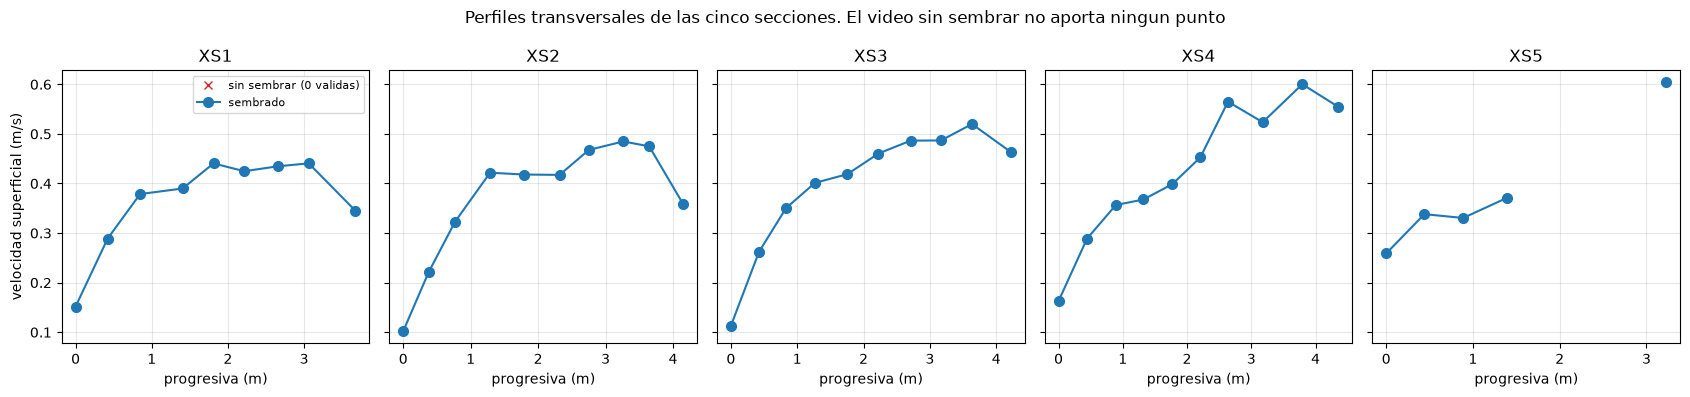

In [15]:
with benchmark.medir("Parte 5: perfiles transversales"):
    # Progresiva de cada vertical a lo largo de su propia seccion, desde el primer punto.
    s_local = np.zeros(N_ESTACIONES)
    for sec in SECCIONES:
        sel = (verticales.seccion == sec).to_numpy()
        p = verticales.loc[sel, ["x", "y"]].to_numpy()
        s_local[sel] = np.hypot(*(p - p[0]).T) * ESCALA
verticales["s_m"] = s_local

for etq in VIDEOS:
    v = v_final[etq]
    if np.isfinite(v).sum() == 0:
        print(f"[{etq:11s}] sin ninguna estacion valida: no hay perfil")
    else:
        print(f"[{etq:11s}] {np.isfinite(v).sum():2d} estaciones, mediana {np.nanmedian(v):.4f} m/s, "
              f"rango {np.nanmin(v):.3f}-{np.nanmax(v):.3f} m/s")

fig, axes = plt.subplots(1, len(SECCIONES), figsize=(17, 4), sharey=True)
for ax, sec in zip(axes, SECCIONES):
    sel = (verticales.seccion == sec).to_numpy()
    for etq, color, marca in zip(VIDEOS, ["tab:red", "tab:blue"], ["x", "o"]):
        v = v_final[etq][sel]
        if np.isfinite(v).any():
            ax.plot(s_local[sel], v, marca + "-", color=color, ms=7, label=etq)
        else:
            ax.plot([], [], marca, color=color, label=f"{etq} (0 validas)")
    ax.set_title(sec); ax.set_xlabel("progresiva (m)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("velocidad superficial (m/s)")
axes[0].legend(fontsize=8)
fig.suptitle("Perfiles transversales de las cinco secciones. El video sin sembrar no aporta "
             "ningun punto", fontsize=12)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig6_perfiles.png", dpi=115, bbox_inches="tight")
plt.show()

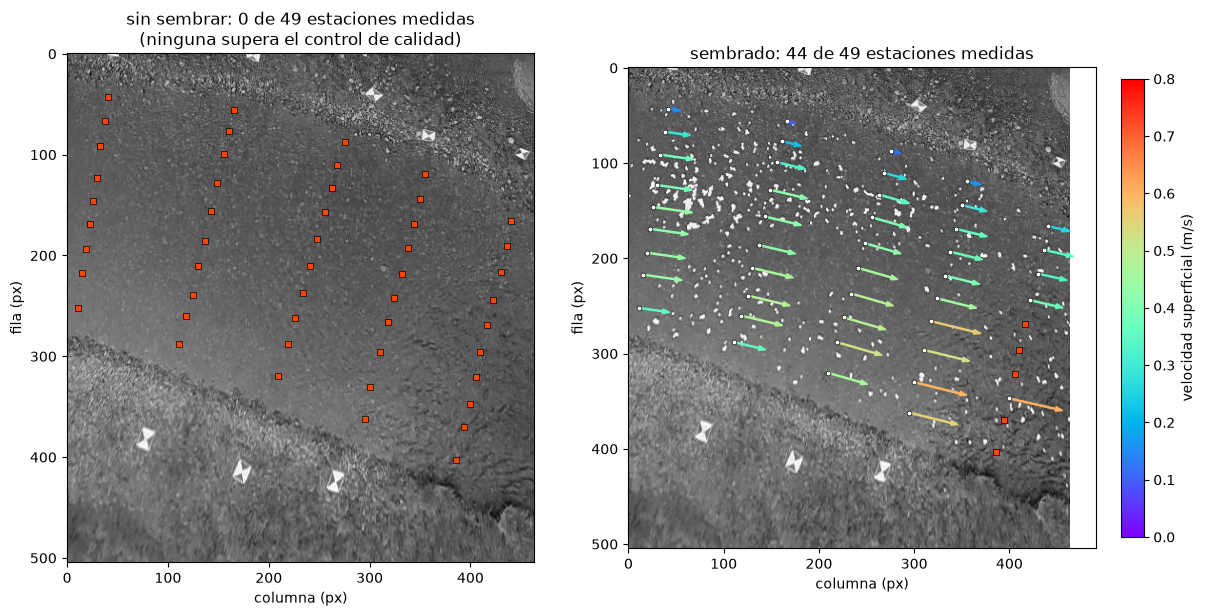

In [16]:
# Las velocidades sobre el fotograma. Cada flecha es una linea de busqueda entera, orientada
# a la normal de su seccion (que es la direccion que STIV recibe, no una medida).
PX_POR_MS = 95

fig, axes = plt.subplots(1, 2, figsize=(16, 8.5))
for ax, etq in zip(axes, VIDEOS):
    ax.imshow(frames[etq], cmap="gray")
    v = v_final[etq]
    for i, (r, l) in enumerate(zip(verticales.itertuples(), lineas)):
        if np.isfinite(v[i]):
            col = plt.cm.rainbow(np.clip(v[i] / 0.8, 0, 1))
            ax.arrow(r.x, r.y, v[i] * PX_POR_MS * l["ux"], v[i] * PX_POR_MS * l["uy"],
                     color=col, width=1.1, head_width=5, length_includes_head=True)
            ax.plot(r.x, r.y, "o", color="w", ms=3.5, mec="k", mew=0.5)
        else:
            ax.plot(r.x, r.y, "s", color="orangered", ms=4.5, mec="k", mew=0.5)
    n_ok = int(np.isfinite(v).sum())
    ax.set_title(f"{etq}: {n_ok} de {N_ESTACIONES} estaciones medidas"
                 + ("" if n_ok else "\n(ninguna supera el control de calidad)"))
    ax.set_xlabel("columna (px)"); ax.set_ylabel("fila (px)")
sm = plt.cm.ScalarMappable(cmap="rainbow", norm=plt.Normalize(0, 0.8))
fig.colorbar(sm, ax=axes, label="velocidad superficial (m/s)", shrink=0.7, pad=0.02)
plt.savefig(DIR_SALIDA / "fig7_vectores.png", dpi=115, bbox_inches="tight")
plt.show()

In [17]:
# Se congela la configuracion completa, comun a los dos videos.
config = dict(
    videos={k: str(v) for k, v in VIDEOS.items()},
    caso_principal=CASO_PRINCIPAL, caso_control=CASO_CONTROL,
    n_frames=int(len(pilas[CASO_PRINCIPAL])), fps=round(FPS, 4), escala_m_px=ESCALA,
    n_secciones=len(SECCIONES), n_estaciones=N_ESTACIONES,
    angulos_seccion_grados={k: round(v, 3) for k, v in angulos.items()},
    v_esperada_ms=V_ESPERADA, ds_px=DS, sigma_antialias_px=SIGMA_ANTIALIAS,
    largo_sti=LARGO_STI, ancho_banda_px=ANCHO_BANDA, paso_banda_px=PASO_BANDA,
    cobertura_min=COBERTURA_MIN, margen_borde_px=MARGEN_BORDE,
    lado_bloque=LADO_BLOQUE, coh_min_bloque=COH_MIN_BLOQUE, sigma_derivada=SIGMA_DERIVADA,
    coh_min_estacion=COH_MIN_ESTACION, contraste_min=CONTRASTE_MIN,
    aceptadas={k: int(valida[k].sum()) for k in VIDEOS},
    coherencia_mediana={k: round(float(np.median(coherencia[k])), 4) for k in VIDEOS},
)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")

perfil = verticales.copy()
for etq in VIDEOS:
    sufijo = etq.replace(" ", "_")
    perfil[f"coherencia_{sufijo}"] = coherencia[etq].round(4)
    perfil[f"contraste_{sufijo}"] = contraste[etq].round(3)
    perfil[f"v_{sufijo}"] = v_final[etq].round(4)
    perfil[f"valida_{sufijo}"] = valida[etq]
perfil.to_csv(SALIDA_PERFIL, index=False)

print(f"Configuracion congelada en: {SALIDA_CONFIG}")
print(f"Perfil guardado en:         {SALIDA_PERFIL}")

Configuracion congelada en: salidas\config_stiv.json
Perfil guardado en:         salidas\perfil_velocidades.csv


---
## Parte 6 - Recursos consumidos

Este es, con diferencia, el caso mas barato del workspace: 99 fotogramas de 464x505 son 23 millones
de pixeles, frente a los 2000 millones del Sile Main Canal. Eso lo hace util justamente para lo
contrario de lo habitual -- aqui se ve el coste **fijo** de cada etapa, el que en los casos grandes
queda enterrado bajo el tiempo de decodificacion.

Se miden las dos pasadas completas, una por video. Que los tiempos salgan practicamente iguales es
en si mismo un dato: **el coste no depende de que haya senal**, solo de cuantos pixeles hay que
leer. Un video sin informacion cuesta exactamente lo mismo de procesar que uno lleno de ella, lo
cual es un buen argumento para hacer el triaje *antes* y no *despues*, como en el caso de Boneyard
Creek.

Maquina donde se miden los tiempos:
  cpu_nucleos_fisicos: 8
  cpu_nucleos_logicos: 12
  ram_total_gb: 42.7
  ram_disponible_gb: 21.7

Tiempo total medido:         17.0 s
Pico de memoria del proceso: 575 MB
Fotogramas procesados (los dos videos): 690
  -> 24.6 ms por fotograma de media

Guardado en: salidas\benchmark_recursos.csv



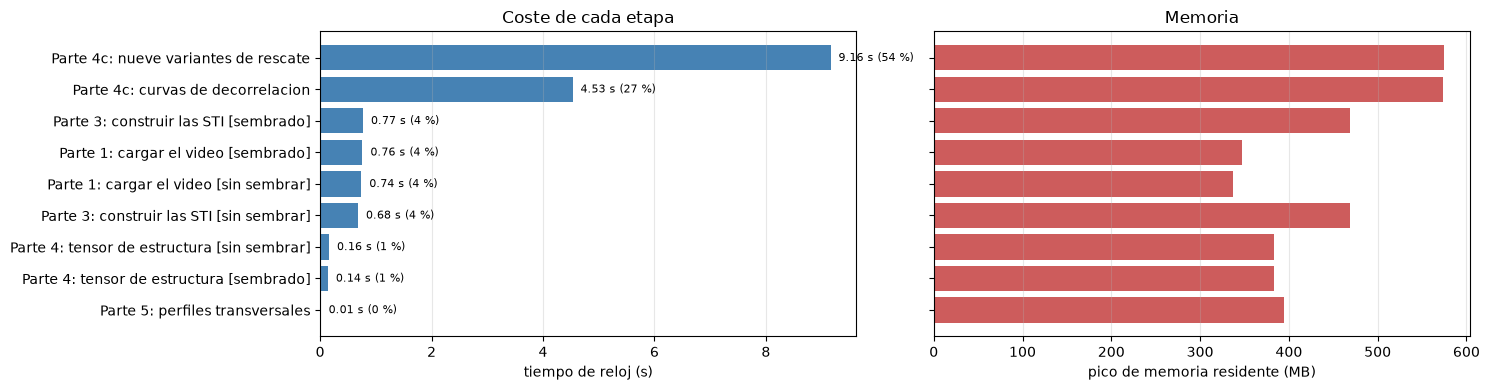

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,lineas,pct_tiempo
0,Parte 1: cargar el video [sin sembrar],0.74,0.78,1.06,336.7,95.4,99.0,NaN,4.4
1,Parte 1: cargar el video [sembrado],0.76,0.92,1.21,347.0,92.8,98.0,NaN,4.5
2,Parte 3: construir las STI [sin sembrar],0.68,0.67,0.99,469.3,-0.7,99.0,49.0,4.0
3,Parte 3: construir las STI [sembrado],0.77,0.72,0.94,469.2,-0.0,98.0,49.0,4.5
4,Parte 4: tensor de estructura [sin sembrar],0.16,0.16,0.97,383.6,0.2,NaN,49.0,0.9
5,Parte 4: tensor de estructura [sembrado],0.14,0.12,0.87,383.6,0.0,NaN,49.0,0.8
6,Parte 4c: nueve variantes de rescate,9.16,8.56,0.93,574.9,1.0,99.0,NaN,54.0
7,Parte 4c: curvas de decorrelacion,4.53,4.41,0.97,573.4,3.9,197.0,NaN,26.7
8,Parte 5: perfiles transversales,0.01,0.00,0.00,394.2,0.0,NaN,NaN,0.1


In [18]:
print("Maquina donde se miden los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)

total_s = tabla_recursos["segundos"].sum()
n_fot = max(benchmark.fotogramas_procesados(), 1)
print(f"\nTiempo total medido:         {total_s:.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")
print(f"Fotogramas procesados (los dos videos): {n_fot}")
print(f"  -> {1000*total_s/n_fot:.1f} ms por fotograma de media")
print(f"\nGuardado en: {SALIDA_BENCHMARK}\n")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
orden = tabla_recursos.sort_values("segundos")
axes[0].barh(orden["etapa"], orden["segundos"], color="steelblue")
axes[0].set_xlabel("tiempo de reloj (s)"); axes[0].set_title("Coste de cada etapa")
axes[0].grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    axes[0].text(seg, y, f"  {seg:.2f} s ({pct:.0f} %)", va="center", fontsize=8)
axes[1].barh(orden["etapa"], orden["ram_pico_mb"], color="indianred")
axes[1].set_xlabel("pico de memoria residente (MB)")
axes[1].set_title("Memoria")
axes[1].grid(axis="x", alpha=0.3); axes[1].set_yticklabels([])
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig8_recursos.png", dpi=110, bbox_inches="tight")
plt.show()

tabla_recursos

---
## Parte 7 - Comparacion con la referencia del dataset

Hasta aqui **no se ha usado ni una sola velocidad de referencia**: de la hoja de validacion se
leyeron en la Parte 2 unicamente las coordenadas. La tercera columna se abre ahora.

Hay dos preguntas distintas que responder, y conviene no mezclarlas:

1. **El video sin sembrar, comparado con la referencia.** No hay nada que comparar: cero
   estaciones aceptadas. La referencia existe -- el aforo se hizo -- pero la imagen no la contiene.
2. **El video sembrado, comparado con la referencia.** Aqui si hay 43 velocidades que enfrentar a
   las 49 del aforo, y el resultado tiene una parte buena y una mala que hay que separar con
   cuidado.

**Esta es la ultima parte con resultados. No se vuelve atras a ajustar nada.**

In [19]:
# ---------------------------------------------------------------------------------------
#  Datos de validacion. Primera y unica vez que aparecen. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
_vel, _sec = [], None
for _, r in _val.iloc[11:].iterrows():
    etiqueta = str(r[0])
    if etiqueta.startswith("XS"):
        _sec = etiqueta
    elif _sec is not None and etiqueta.replace(".", "").isdigit():
        _vel.append(float(r[2]))
V_REFERENCIA = np.array(_vel)
# ---------------------------------------------------------------------------------------
assert len(V_REFERENCIA) == N_ESTACIONES

comparacion = verticales[["seccion", "x", "y", "s_m", "cobertura"]].copy()
comparacion["v_ref"] = V_REFERENCIA
for etq in VIDEOS:
    comparacion[f"v_{etq.replace(' ', '_')}"] = v_final[etq]

print("=" * 78)
for etq in VIDEOS:
    v = v_final[etq]
    ok = np.isfinite(v)
    print(f"[{etq}]")
    if ok.sum() == 0:
        print(f"  0 estaciones aceptadas de {N_ESTACIONES}. No hay nada que comparar con la "
              "referencia.")
        print(f"  La referencia para esas mismas verticales existe y vale "
              f"{V_REFERENCIA.mean():.3f} m/s de media,")
        print("  o sea que habia agua corriendo: lo que falta es textura en la imagen, no flujo.")
    else:
        d = v[ok] - V_REFERENCIA[ok]
        print(f"  {ok.sum()} estaciones aceptadas de {N_ESTACIONES}")
        print(f"  media STIV {v[ok].mean():.4f} m/s   |   media referencia "
              f"{V_REFERENCIA[ok].mean():.4f} m/s")
        print(f"  sesgo {d.mean():+.4f} m/s ({100*d.mean()/V_REFERENCIA[ok].mean():+.1f} %)   "
              f"RMSE {np.sqrt((d**2).mean()):.4f} m/s   "
              f"r = {np.corrcoef(v[ok], V_REFERENCIA[ok])[0,1]:+.3f}")
    print("-" * 78)
print("=" * 78)

[sin sembrar]
  0 estaciones aceptadas de 49. No hay nada que comparar con la referencia.
  La referencia para esas mismas verticales existe y vale 0.418 m/s de media,
  o sea que habia agua corriendo: lo que falta es textura en la imagen, no flujo.
------------------------------------------------------------------------------
[sembrado]
  44 estaciones aceptadas de 49
  media STIV 0.3891 m/s   |   media referencia 0.4172 m/s
  sesgo -0.0281 m/s (-6.7 %)   RMSE 0.1645 m/s   r = -0.087
------------------------------------------------------------------------------


### La parte buena y la parte mala del video sembrado

**La media de la seccion se acerca**: STIV da 0.389 m/s de media frente a los 0.417 del aforo, un
6.7 % por debajo, sobre 44 verticales. Para una tecnica que solo ve la superficie y a la que nadie
le ha dado un solo dato de campo, eso no esta mal.

**El perfil transversal no correla**: $r \approx 0$. STIV mide un perfil que crece de forma
monotona hacia la orilla mas cercana a la camara, mientras que la referencia baja en las **dos**
orillas, como cabria esperar de un canal.

La pregunta que decide si esto es un fallo de STIV es facil de plantear y merece la pena
responderla, porque la respuesta cambia por completo la lectura del caso: **¿mide otra tecnica de
imagen lo mismo que STIV, o algo distinto?** Si otra tecnica reprodujera el perfil de la
referencia, el problema seria de STIV. Si mide lo mismo que STIV, entonces lo que discrepa es la
imagen frente al dato de campo, y no el algoritmo.

La celda siguiente lo comprueba con un **PIV de correlacion ensemble**, que no comparte con STIV ni
el planteamiento (correla parches 2D entre pares de fotogramas, no busca orientaciones en una
imagen espacio-temporal) ni una sola linea de codigo.

In [20]:
# PIV de correlacion ensemble: la correlacion cruzada normalizada de cada parche se promedia
# sobre TODOS los pares de fotogramas consecutivos antes de buscar el pico. Es el metodo
# estandar cuando la senal por par es debil, y aqui hace de arbitro independiente: no
# comparte con STIV mas que el video.
RADIO_PARCHE = 20             # semilado del parche, px
RADIO_BUSQUEDA = 14           # desplazamiento maximo explorado, px
PASO_REJILLA = 20             # separacion entre nodos, px


def piv_ensemble(pila, radio, busqueda, paso):
    """Campo de desplazamiento por correlacion ensemble. Devuelve X, Y, U, V, C."""
    n = (pila - pila.mean(axis=0)) / (pila.std(axis=0) + 1e-6)
    alto, ancho = n.shape[1:]
    xs = np.arange(radio + busqueda, ancho - radio - busqueda, paso)
    ys = np.arange(radio + busqueda, alto - radio - busqueda, paso)
    U = np.full((len(ys), len(xs)), np.nan)
    V, Cc = U.copy(), U.copy()
    for jj, y0 in enumerate(ys):
        for ii, x0 in enumerate(xs):
            acc = None
            for k in range(len(n) - 1):
                A = n[k, y0 - radio:y0 + radio, x0 - radio:x0 + radio]
                B = n[k + 1, y0 - radio - busqueda:y0 + radio + busqueda,
                      x0 - radio - busqueda:x0 + radio + busqueda]
                r = cv2.matchTemplate(B, A, cv2.TM_CCOEFF_NORMED)
                acc = r if acc is None else acc + r
            acc /= (len(n) - 1)
            j, i = np.unravel_index(acc.argmax(), acc.shape)
            U[jj, ii], V[jj, ii], Cc[jj, ii] = i - busqueda, j - busqueda, acc.max()
    X, Y = np.meshgrid(xs, ys)
    return X, Y, U, V, Cc


with benchmark.medir("Parte 7: PIV de correlacion ensemble (arbitro independiente)",
                     n_frames=len(pilas[CASO_CONTROL])):
    Xg, Yg, Ug, Vg, Cg = piv_ensemble(pilas[CASO_CONTROL], RADIO_PARCHE,
                                      RADIO_BUSQUEDA, PASO_REJILLA)

vel_piv = np.hypot(Ug, Vg) * ESCALA / DT
vel_piv = np.where(Cg > 0.25, vel_piv, np.nan)

# Se interpola el campo PIV en las mismas verticales del aforo.
from scipy.interpolate import griddata
nodos = np.column_stack([Xg.ravel(), Yg.ravel()])
valores = vel_piv.ravel()
finito = np.isfinite(valores)
comparacion["v_piv"] = griddata(nodos[finito], valores[finito],
                                verticales[["x", "y"]].to_numpy(), method="linear")

cmp_piv = comparacion.dropna(subset=["v_piv"])
d_piv = cmp_piv.v_piv - cmp_piv.v_ref
cmp_stiv = comparacion.dropna(subset=["v_sembrado"])
d_stiv = cmp_stiv.v_sembrado - cmp_stiv.v_ref
ambos = comparacion.dropna(subset=["v_piv", "v_sembrado"])

print("=" * 78)
print("ARBITRO INDEPENDIENTE: dos tecnicas de imagen distintas contra la misma referencia")
print("=" * 78)
print(f"  STIV vs referencia ({len(cmp_stiv):2d} pts):  sesgo {d_stiv.mean():+.4f}  "
      f"RMSE {np.sqrt((d_stiv**2).mean()):.4f}  r = {np.corrcoef(cmp_stiv.v_sembrado, cmp_stiv.v_ref)[0,1]:+.3f}")
print(f"  PIV  vs referencia ({len(cmp_piv):2d} pts):  sesgo {d_piv.mean():+.4f}  "
      f"RMSE {np.sqrt((d_piv**2).mean()):.4f}  r = {np.corrcoef(cmp_piv.v_piv, cmp_piv.v_ref)[0,1]:+.3f}")
print(f"\n  STIV vs PIV        ({len(ambos):2d} pts):  "
      f"r = {np.corrcoef(ambos.v_stiv if 'v_stiv' in ambos else ambos.v_sembrado, ambos.v_piv)[0,1]:+.3f}  "
      f"RMSE {np.sqrt(((ambos.v_sembrado-ambos.v_piv)**2).mean()):.4f} m/s")
print("=" * 78)
print("\nLas dos tecnicas de imagen se parecen mucho mas entre si que cualquiera de ellas a la")
print("referencia. La discrepancia del perfil transversal es de la imagen contra el dato de")
print("campo, no de STIV: un algoritmo completamente distinto, sobre el mismo video, la repite.")

  [bench] Parte 7: PIV de correlacion ensemble (arbitro independiente): 43.0 s | CPU 41.2 s (1.0 nucleos) | RAM pico 580 MB


ARBITRO INDEPENDIENTE: dos tecnicas de imagen distintas contra la misma referencia
  STIV vs referencia (44 pts):  sesgo -0.0281  RMSE 0.1645  r = -0.087
  PIV  vs referencia (36 pts):  sesgo +0.0264  RMSE 0.1532  r = -0.009

  STIV vs PIV        (32 pts):  r = +0.974  RMSE 0.0339 m/s

Las dos tecnicas de imagen se parecen mucho mas entre si que cualquiera de ellas a la
referencia. La discrepancia del perfil transversal es de la imagen contra el dato de
campo, no de STIV: un algoritmo completamente distinto, sobre el mismo video, la repite.


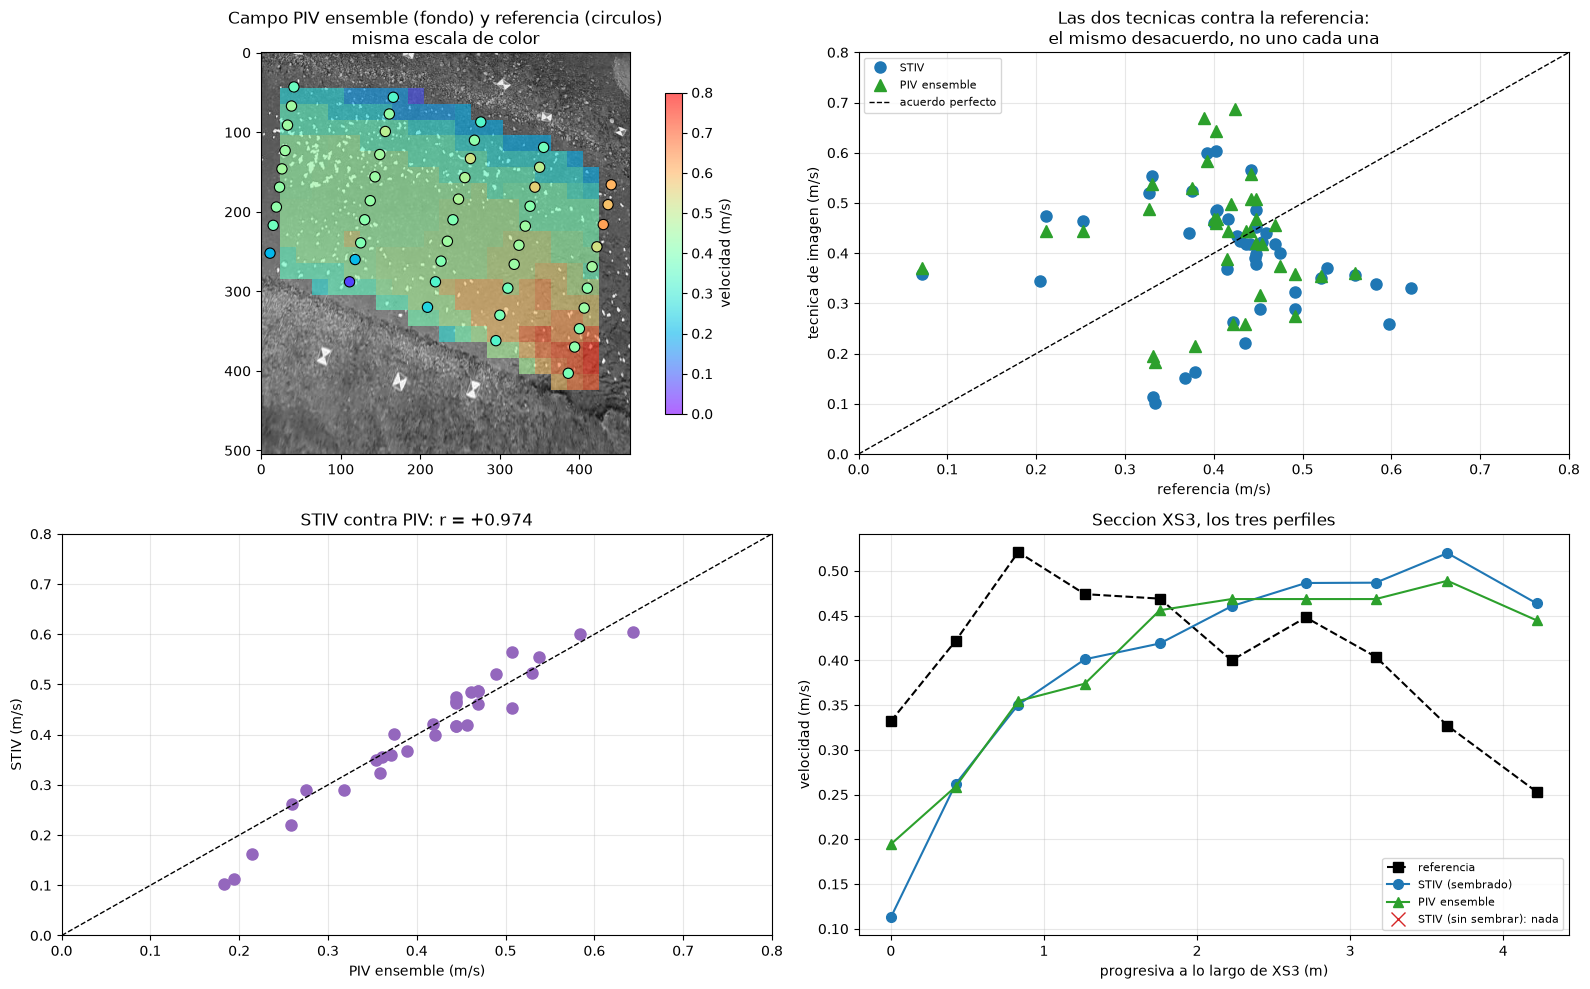

In [21]:
fig = plt.figure(figsize=(16, 10))

# 1. El campo PIV con la referencia encima, en la misma escala de color.
ax = fig.add_subplot(2, 2, 1)
ax.imshow(frames[CASO_CONTROL], cmap="gray")
m = ax.pcolormesh(Xg, Yg, vel_piv, cmap="rainbow", alpha=0.6, vmin=0, vmax=0.8, shading="auto")
ax.scatter(comparacion.x, comparacion.y, c=comparacion.v_ref, cmap="rainbow",
           vmin=0, vmax=0.8, s=55, edgecolors="k", linewidths=0.8)
fig.colorbar(m, ax=ax, label="velocidad (m/s)", shrink=0.8)
ax.set_title("Campo PIV ensemble (fondo) y referencia (circulos)\nmisma escala de color")

# 2. STIV y PIV frente a la referencia.
ax = fig.add_subplot(2, 2, 2)
ax.plot(cmp_stiv.v_ref, cmp_stiv.v_sembrado, "o", ms=8, color="tab:blue", label="STIV")
ax.plot(cmp_piv.v_ref, cmp_piv.v_piv, "^", ms=8, color="tab:green", label="PIV ensemble")
lim = [0.0, 0.8]
ax.plot(lim, lim, "k--", lw=1, label="acuerdo perfecto")
ax.set_xlabel("referencia (m/s)"); ax.set_ylabel("tecnica de imagen (m/s)")
ax.set_title("Las dos tecnicas contra la referencia:\nel mismo desacuerdo, no uno cada una")
ax.set_xlim(lim); ax.set_ylim(lim); ax.grid(alpha=0.3); ax.legend(fontsize=8)

# 3. STIV contra PIV.
ax = fig.add_subplot(2, 2, 3)
ax.plot(ambos.v_piv, ambos.v_sembrado, "o", ms=8, color="tab:purple")
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("PIV ensemble (m/s)"); ax.set_ylabel("STIV (m/s)")
ax.set_title(f"STIV contra PIV: r = "
             f"{np.corrcoef(ambos.v_sembrado, ambos.v_piv)[0,1]:+.3f}")
ax.set_xlim(lim); ax.set_ylim(lim); ax.grid(alpha=0.3)

# 4. Perfiles de una seccion completa, los tres juntos.
ax = fig.add_subplot(2, 2, 4)
sel = comparacion.seccion == "XS3"
sub = comparacion[sel]
ax.plot(sub.s_m, sub.v_ref, "ks--", ms=7, label="referencia")
ax.plot(sub.s_m, sub.v_sembrado, "o-", color="tab:blue", ms=7, label="STIV (sembrado)")
ax.plot(sub.s_m, sub.v_piv, "^-", color="tab:green", ms=7, label="PIV ensemble")
ax.plot(sub.s_m, sub.v_sin_sembrar if "v_sin_sembrar" in sub else np.full(len(sub), np.nan),
        "x", color="tab:red", ms=10, label="STIV (sin sembrar): nada")
ax.set_xlabel("progresiva a lo largo de XS3 (m)"); ax.set_ylabel("velocidad (m/s)")
ax.set_title("Seccion XS3, los tres perfiles")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig9_arbitro_independiente.png", dpi=115, bbox_inches="tight")
plt.show()

In [22]:
resumen = pd.DataFrame([
    dict(concepto="Estaciones aceptadas, video SIN SEMBRAR",
         valor=int(valida[CASO_PRINCIPAL].sum()), unidad=f"de {N_ESTACIONES}"),
    dict(concepto="Estaciones aceptadas, video SEMBRADO",
         valor=int(valida[CASO_CONTROL].sum()), unidad=f"de {N_ESTACIONES}"),
    dict(concepto="Coherencia mediana, sin sembrar",
         valor=round(float(np.median(coherencia[CASO_PRINCIPAL])), 4), unidad="-"),
    dict(concepto="Coherencia mediana, sembrado",
         valor=round(float(np.median(coherencia[CASO_CONTROL])), 4), unidad="-"),
    dict(concepto="Coherencia MAXIMA, sin sembrar",
         valor=round(float(coherencia[CASO_PRINCIPAL].max()), 4), unidad=f"umbral {COH_MIN_ESTACION}"),
    dict(concepto="Contraste temporal mediano, sin sembrar",
         valor=round(float(np.median(contraste[CASO_PRINCIPAL])), 3), unidad="niveles de gris"),
    dict(concepto="Contraste temporal mediano, sembrado",
         valor=round(float(np.median(contraste[CASO_CONTROL])), 3), unidad="niveles de gris"),
    dict(concepto="Velocidad media STIV (sembrado)",
         valor=round(float(cmp_stiv.v_sembrado.mean()), 4), unidad="m/s"),
    dict(concepto="Velocidad media de referencia (mismas verticales)",
         valor=round(float(cmp_stiv.v_ref.mean()), 4), unidad="m/s"),
    dict(concepto="Sesgo STIV vs referencia",
         valor=round(float(d_stiv.mean()), 4), unidad="m/s"),
    dict(concepto="RMSE STIV vs referencia",
         valor=round(float(np.sqrt((d_stiv ** 2).mean())), 4), unidad="m/s"),
    dict(concepto="Correlacion STIV vs referencia",
         valor=round(float(np.corrcoef(cmp_stiv.v_sembrado, cmp_stiv.v_ref)[0, 1]), 4), unidad="-"),
    dict(concepto="Correlacion PIV vs referencia",
         valor=round(float(np.corrcoef(cmp_piv.v_piv, cmp_piv.v_ref)[0, 1]), 4), unidad="-"),
    dict(concepto="Correlacion STIV vs PIV",
         valor=round(float(np.corrcoef(ambos.v_sembrado, ambos.v_piv)[0, 1]), 4), unidad="-"),
    dict(concepto="Escala (dada por el dataset)", valor=ESCALA, unidad="m/px"),
    dict(concepto="Caudal", valor=np.nan, unidad="no calculable: el dataset no da batimetria"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
comparacion.to_csv(DIR_SALIDA / "comparacion_referencia.csv", index=False)
print(resumen.to_string(index=False))
print(f"\nGuardado en: {SALIDA_RESUMEN} y {DIR_SALIDA / 'comparacion_referencia.csv'}")

                                         concepto   valor                                     unidad
          Estaciones aceptadas, video SIN SEMBRAR  0.0000                                      de 49
             Estaciones aceptadas, video SEMBRADO 44.0000                                      de 49
                  Coherencia mediana, sin sembrar  0.1961                                          -
                     Coherencia mediana, sembrado  0.9271                                          -
                   Coherencia MAXIMA, sin sembrar  0.5948                                 umbral 0.7
          Contraste temporal mediano, sin sembrar  0.7080                            niveles de gris
             Contraste temporal mediano, sembrado  6.7360                            niveles de gris
                  Velocidad media STIV (sembrado)  0.3891                                        m/s
Velocidad media de referencia (mismas verticales)  0.4172                                  

---
## Conclusiones

1. **El video sin sembrar no es medible por velocimetria de imagen.** Cero estaciones de 49 superan
   un control de calidad cuyos umbrales vienen heredados de otros casos y no se han tocado aqui. La
   coherencia maxima de las 49 no llega al umbral, y el contraste maximo tampoco. No es una medida
   mala: es la ausencia de medida.

   Y el limite no es del procesado. Las **nueve variantes de rescate** de la Parte 4c -- muestreo
   hasta `DS = 1`, bandas de hasta 60 px, paso alto espacial, una STI por seccion entera, y todas
   combinadas -- dan cero estaciones sin excepcion, y su correlacion con la referencia interna va de
   -0.12 a +0.45, erratica como corresponde al ruido. La unica que sube la coherencia de forma
   apreciable (el paso alto, 0.196 -> 0.452) lo hace **sin** mejorar el acuerdo con la verdad, que
   es la firma de un filtro que fabrica orientacion en vez de encontrarla. La curva de
   decorrelacion explica por que: el patron de la superficie vale **0.06 en el salto de un
   fotograma**, y su curva es plana. No hay nada grabado que seguir, y ningun algoritmo lo arregla.
   Lo que lo arreglaria es sembrar o grabar mas deprisa, o sea la adquisicion.

2. **El sembrado lo cambia todo, y es lo unico que cambia.** Mismo rio, misma camara, mismo
   encuadre, misma escala, mismos 99 fotogramas, misma configuracion del algoritmo hasta la ultima
   constante. La coherencia mediana pasa de 0.20 a 0.93. Es la definicion de un experimento
   controlado, y el resultado es que **la limitacion esta en el agua, no en el metodo**.

3. **Sobre el video sembrado, STIV se acerca a la media de la seccion (-6.7 %) y no reproduce el
   perfil transversal.** El arbitro independiente -- un PIV de correlacion ensemble, sin una linea
   de codigo en comun -- reproduce el mismo desacuerdo con la referencia: r = -0.01 frente al
   r = -0.09 de STIV. Y entre ellas dos, **r = +0.97 con un RMSE de 0.034 m/s**, o sea que
   coinciden hasta 3 cm/s. Dos tecnicas distintas que coinciden entre si y
   discrepan igual de un dato de campo apuntan a que lo que se compara no es lo mismo: lo mas
   probable es que la referencia sea velocidad **promediada en la vertical** y no superficial, en
   cuyo caso el cociente entre ambas no es constante a lo ancho de la seccion, sino que crece justo
   donde el calado disminuye, que es donde estan las discrepancias.

   Este notebook **no ajusta ningun coeficiente para cerrar esa diferencia**. Ajustar un alfa por
   vertical hasta que el perfil coincidiera no seria una validacion, seria un calco.

4. **No hay caudal, y no lo habra con este dataset.** Falta la batimetria.

## Limitaciones conocidas

1. **Solo 99 fotogramas a 5 Hz.** Es el video mas corto y mas lento del workspace, y obliga a
   bloques de tensor de 24 px en vez de 64. Menos bloques significa una mediana ponderada con menos
   de que hacer mediana.
2. **Las secciones XS1 y XS5 estan pegadas al borde del fotograma.** Sus lineas se recortan a
   cobertura 0.52-0.81, asi que miden sobre un tramo mas corto y con peor estadistica. Se nota
   exactamente donde cabe esperarlo: **las 5 verticales rechazadas del video sembrado estan todas
   en XS5**, y todas por coherencia (0.53 a 0.69, justo por debajo del umbral de 0.70), no por
   falta de contraste -- el suyo va de 4.5 a 7.8, muy por encima del minimo. XS1 se salva porque
   su recorte, aun siendo el mayor, deja las lineas en la zona de mas trazador.
3. **La direccion del flujo se impone por seccion, no por vertical.** El rio gira dentro del
   encuadre (de +6 a +39 grados medidos), y una recta por seccion es una aproximacion. Se probo
   acortar las lineas hasta 56 px para reducir el efecto de la curvatura y el resultado no cambio,
   asi que la curvatura no explica la discrepancia del perfil.
4. **La referencia puede no ser una velocidad superficial.** El dataset no lo dice. Es la
   explicacion mas probable del punto 3 de las conclusiones, pero no esta confirmada.
5. **Los videos vienen comprimidos con perdida**, igual que en el Bradano.
6. **Solo se ha procesado la camara GoPro.** El dataset trae ademas una pareja seeded/unseeded
   tomada con un UAS, con su propio fichero de validacion. Una comprobacion rapida con correlacion
   ensemble da el mismo resultado cualitativo (el UAS sin sembrar tampoco tiene senal), pero no se
   ha procesado con este notebook.

## Equivalencia con los otros casos del workspace

| | Sile Main Canal | Boneyard Creek | Hommerich | Bradano | **Arrow** |
|---|---|---|---|---|---|
| Camara | dron cenital | oblicua fija | oblicua fija | dron cenital | mastil, ortorrectificada |
| Escala | deducida | **no existe** | de GCP RTK | dada | dada |
| Estabilizacion | script propio | no hace falta | no hace falta | la trae el dataset | la trae el dataset |
| Trazador | espuma continua | espuma fina | natural | particulas dispersas | **sembrado / ninguno** |
| Secciones | 1 | 1 | 1 | 1 | **5** |
| Direccion del flujo | una global | una global | normal a la seccion | una global | **una por seccion** |
| Fotogramas | 250 | 250 | 122 | 600 | **99** |
| Lado del bloque | 64 | 64 | 64 | 64 | **24** |
| QC | coherencia | contraste | contraste + coherencia | brillo + coherencia | contraste + coherencia + cobertura |
| Resultado | caudal | velocidad afin | caudal | velocidad m/s | **el sembrado es la variable** |

## Resumen de las constantes `>>> AJUSTABLE <<<`

| Parte | Constante | Valor | De donde sale |
|---|---|---|---|
| 2 | `ESCALA` | 0.0174 m/px | `Readme.txt` del dataset |
| 2 | `COBERTURA_MIN`, `MARGEN_BORDE` | 0.50, 5 px | geometria del encuadre |
| 3 | `V_ESPERADA` | 0.45 m/s | correlacion de parches, a priori |
| 3 | `N_FRAMES` | 99 | el video entero |
| 3 | `LARGO_STI` | 48 muestras | 4.2 m; mas largo se sale del fotograma |
| 3 | `ANCHO_BANDA`, `PASO_BANDA` | 6, 3 px | 24 % de la separacion entre verticales |
| 4 | `LADO_BLOQUE` | 24 | solo hay 99 fotogramas |
| 4 | `COH_MIN_BLOQUE`, `SIGMA_DERIVADA` | 0.45, 1.2 | en proporcion al bloque |
| 4b | `COH_MIN_ESTACION` | 0.70 | **el mismo que Sile y Bradano** |
| 4b | `CONTRASTE_MIN` | 2.0 | hueco medido entre los dos videos |

La direccion del flujo **no** es una constante ajustable: sale de las coordenadas de las secciones
del propio dataset.

## Y despues

`video_velocidad.py`, en esta misma carpeta, repite este STIV en ventanas deslizantes sobre los dos
videos a la vez y escribe `salidas/velocidad_tiempo_real.mp4`, con los dos videos lado a lado y el
mismo tratamiento en ambos. **Duplica las constantes de este notebook**: si se cambia una aqui, hay
que cambiarla alli.